# Run Plan Disclosure Pacing: Diary Data Pipeline (MCO2 Milestone 1)

**HCI2000 · Bernandino, Galman, Muros, Punsalan**

> ⚠️ **This notebook currently runs on SYNTHETIC data** generated by `generate_dummy_diary.py` (seed 2000).
> The built-in effects (Full Plan minus Current Only: RPE +1.0, mental demand +1.5 on the 0–10 form scale) exist only to check that the pipeline can find them. **None of the numbers below are final results.**

### Research questions
| RQ | Question | Main measures |
|---|---|---|
| **RQ1** | How does disclosure pacing (Full Plan vs Current Only) affect runners' cognitive load? | NASA-TLX (mental demand as the main indicator), diary text on what runners had to keep track of |
| **RQ2** | How does disclosure pacing affect runners' perceived exertion? | Borg RPE 6–20, diary text on pacing decisions |
| **RQ3** | How is cognitive load related to perceived exertion, and does this differ by condition? | Mental demand × RPE (within and between runners) |

### Expected relationships (Section 3.6 of the proposal; explored, not tested as confirmatory hypotheses)
1. **Cognitive load:** Full Plan > Current Only, mainly on mental demand.
2. **Perceived exertion:** RPE differs between conditions (non-directional). Anticipatory regulation predicts Full Plan runners hold back before hard sessions and push before easy ones or the final session.
3. **Load and exertion:** higher mental demand goes with higher RPE; the relationship may differ by condition.

### Pipeline overview
| Stage | Section | Output |
|---|---|---|
| Load + schema check | 1 | raw responses mapped to short field names |
| Cleaning (12 checks) | 2 | `cleaning_log.csv`, cleaned rows |
| Preparation | 3 | `sessions.csv` (one row per participant × scheduled session), `tlx_long.csv`, `participant_summary.csv`, `text_responses.csv`, `data_dictionary.csv` |
| Pipeline tests | 4 | unit tests + known-answer tests against the synthetic ground truth |
| Analysis | 5–9 | adherence, RQ1, RQ2, RQ3, LLM-assisted content analysis, sensitivity checks |

**To run:** put the two CSVs in `data/`, then *Run all*. Works in Jupyter, VS Code, or Google Colab (upload the `data/` folder). For the real study, change the settings in Section 0 (`RAW_FILE`, `KEY_FILE`, `N_WEEKS = 2`).

## 0. Setup and study settings
Every study-specific assumption lives in this one cell, so switching from synthetic to real data means editing settings, not code.

In [1]:
import itertools
import json
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

# ---------- Files ----------
DATA_DIR = Path("data")
RAW_FILE = DATA_DIR / "SYNTHETIC_diary_responses.csv"   # Google Forms export (File > Download > CSV)
KEY_FILE = DATA_DIR / "SYNTHETIC_participant_key.csv"   # participant_code, condition, experience_group
OUT_DIR = Path("processed")
FIG_DIR = OUT_DIR / "figures"
LLM_DIR = OUT_DIR / "llm_coding"
for d in (OUT_DIR, FIG_DIR, LLM_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Study design ----------
STUDY_START = pd.Timestamp("2026-11-09")      # Monday of Week 1
N_WEEKS = 3                                    # synthetic data has 3 weeks; the real study has 2 (Nov 9-21)
PLAN = ["Easy run", "Interval run", "Easy run", "Tempo run", "Long run"]   # session order within each week
SESSIONS_PER_WEEK = len(PLAN)
HARD_TYPES = {"Interval run", "Tempo run", "Long run"}
CONDITIONS = ["Full Plan", "Current Only"]

# ---------- Cleaning rules ----------
LATE_THRESHOLD_H = 2.0          # the form asks for entries within 2 hours of finishing
VERY_LATE_H = 24.0              # beyond this, recall is unreliable
DUPLICATE_POLICY = "last"       # "last" = treat a resubmission as a correction; "first" = keep the original
WITHDRAWAL_RUN = 3              # this many missing sessions in a row at the end of the plan = withdrawal
CONFIRMED_WITHDRAWALS = {}      # from researcher records, e.g. {"R03": 8} = withdrew after session index 8
DATA_WITHDRAWN = set()          # participants who asked for their data to be removed (dropped entirely)
PERFORMANCE_REVERSED = False    # True if the form's Performance scale has 0 = failure (NASA-TLX standard is 0 = perfect)
SEED = 2000
rng = np.random.default_rng(SEED)

# ---------- Chart style (validated categorical palette, colorblind-safe for 2-3 series) ----------
COND_COLORS = {"Full Plan": "#2a78d6", "Current Only": "#eb6834"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
STATUS_COLORS = {"prescribed": "#0ca30c", "modified": "#fab219", "skipped": "#d03b3b",
                 "missing": "#e1e0d9", "withdrawn": "#f0efec"}
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 110, "axes.axisbelow": True,
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print("Settings loaded. Expected sessions per participant:", N_WEEKS * SESSIONS_PER_WEEK)

Settings loaded. Expected sessions per participant: 15


## 1. Load raw data and check the schema
Google Forms exports use the full question text as column headers, and editing a question changes the header. Instead of hard-coding headers, each field is found by a **pattern on the question text**. The pipeline stops with a clear error if a required question is missing or matches more than one column, and logs any extra columns.

In [2]:
FIELD_PATTERNS = {
    "timestamp":        r"^timestamp$",
    "email":            r"^email address$",
    "participant_code": r"^participant code",
    "session_date":     r"^date of the session",
    "finish_time":      r"^what time did you finish",
    "week":             r"^week of the plan",
    "session":          r"^session number",
    "session_type":     r"^session type",
    "status":           r"^did you complete the session",
    "modify_reason":    r"^briefly describe what you changed",
    "skip_reason":      r"^why did you skip",
    "skip_note":        r"^is there anything else you'd like to add",
    "rpe":              r"^how hard did your body feel",
    "q_pacing":         r"^did what you knew about your upcoming sessions",
    "tlx_mental":       r"^mental demand",
    "tlx_physical":     r"^physical demand",
    "tlx_temporal":     r"^temporal demand",
    "tlx_performance":  r"^performance",
    "tlx_effort":       r"^effort",
    "tlx_frustration":  r"^frustration",
    "q_tracking":       r"^what did you have to think about",
    "q_plan_mind":      r"^did anything on your mind about the plan",
    "q_other":          r"^is there anything else about today",
}
OPTIONAL_FIELDS = {"email", "skip_note", "q_other"}
TLX_COLS = ["tlx_mental", "tlx_physical", "tlx_temporal", "tlx_performance", "tlx_effort", "tlx_frustration"]
RATING_COLS = ["rpe"] + TLX_COLS
TEXT_QS = {"q_pacing": "Did what you knew about upcoming sessions affect how hard you pushed?",
           "q_tracking": "What did you have to think about or keep track of?",
           "q_plan_mind": "Did anything on your mind about the plan make the run easier or harder?",
           "q_other": "Anything else that stood out?"}


class CleaningLog:
    """Collects one record per problem found, so every change to the data is traceable."""
    def __init__(self):
        self.records = []

    def add(self, step, issue, action, rows=None, detail=""):
        if rows is not None and len(rows) == 0:
            return                      # check ran, nothing found
        if rows is None:
            self.records.append(dict(step=step, participant=None, week=None, session=None,
                                     issue=issue, action=action, detail=detail))
            return
        def num(v):   # "Week 2" / "Session 3" (before parsing) and 2 / 3 (after) both become 2 / 3
            m = re.search(r"\d+", str(v)) if pd.notna(v) else None
            return int(m.group()) if m else None
        for _, r in rows.iterrows():
            self.records.append(dict(step=step, participant=r.get("participant_code"), week=num(r.get("week")),
                                     session=num(r.get("session")), issue=issue, action=action,
                                     detail=detail(r) if callable(detail) else detail))

    def frame(self):
        return pd.DataFrame(self.records, columns=["step", "participant", "week", "session", "issue", "action", "detail"])


def _norm_header(h):
    return re.sub(r"\s+", " ", str(h).replace("’", "'").replace("‘", "'")).strip().lower()


def match_columns(columns, log=None):
    """Map raw question headers to short field names. Raises on missing or ambiguous required fields."""
    rename, problems = {}, []
    for field, pattern in FIELD_PATTERNS.items():
        hits = [c for c in columns if re.search(pattern, _norm_header(c))]
        if len(hits) > 1:
            problems.append(f"'{field}' matches {len(hits)} columns: {hits}")
        elif not hits and field not in OPTIONAL_FIELDS:
            problems.append(f"required field '{field}' not found (pattern {pattern!r})")
        elif hits:
            rename[hits[0]] = field
    if problems:
        raise ValueError("Schema check failed:\n  " + "\n  ".join(problems))
    extra = [c for c in columns if c not in rename]
    if extra and log is not None:
        log.add("1 schema", "unexpected column(s)", "dropped", detail="; ".join(extra))
    return rename


def load_raw(path, log):
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    rename = match_columns(list(raw.columns), log)
    df = raw[list(rename)].rename(columns=rename)
    for f in OPTIONAL_FIELDS - set(df.columns):
        df[f] = ""
    df.insert(0, "row_id", np.arange(len(df)))
    return df


def load_key(path):
    key = pd.read_csv(path, dtype=str).apply(lambda s: s.str.strip())
    key["participant_code"] = key["participant_code"].map(normalize_code)
    bad = set(key["condition"]) - set(CONDITIONS)
    if bad or key["participant_code"].isna().any() or key["participant_code"].duplicated().any():
        raise ValueError(f"Participant key problem: unknown conditions {bad}, or blank/duplicate codes")
    return key


def normalize_code(value):
    """'r3', ' R03 ', 'R-3', '3' -> 'R03'. Anything else -> None."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    m = re.fullmatch(r"R?[-_ ]?0*(\d{1,3})", str(value).strip().upper())
    return f"R{int(m.group(1)):02d}" if m else None


log = CleaningLog()
raw = load_raw(RAW_FILE, log)
key = load_key(KEY_FILE)
print(f"Raw responses: {len(raw)} rows × {raw.shape[1]} fields | Participants in key: {len(key)}")
print(key.groupby(["condition", "experience_group"]).size().unstack().to_string())
raw.head(3)

Raw responses: 168 rows × 24 fields | Participants in key: 12
experience_group  Experienced  Novice
condition                            
Current Only                3       3
Full Plan                   3       3


,row_id,timestamp,email,participant_code,session_date,finish_time,week,session,session_type,status,modify_reason,skip_reason,skip_note,rpe,q_pacing,tlx_mental,tlx_physical,tlx_temporal,tlx_performance,tlx_effort,tlx_frustration,q_tracking,q_plan_mind,q_other
0,0,11/9/2026 7:50:16,r03.dummy@example.com,R03,11/9/2026,6:58:00 AM,Week 1,Session 1,Easy run,As prescribed,,,,9 - Very light,"Yes, I didn't know what was coming next so I kept some energy in reserve.",4,1,2,2,0,3,Just the time on my watch.,Neither,
1,1,11/9/2026 8:03:03,r01.dummy@example.com,R01,11/9/2026,7:25:00 AM,Week 1,Session 1,Easy run,As prescribed,,,,12,Somewhat. Knowing the interval run is next made me careful with my pace.,3,6,4,1,5,2,"Nothing much, just laced up and went. Looked ahead at the plan to sort out m...",Nothing,Slept badly last night.
2,2,11/9/2026 8:51:09,r06.dummy@example.com,R06,11/9/2026,8:25:00 AM,Week 1,Session 1,Easy run,Modified,"Cut it 10 minutes short, ran out of time before work.",,,10,No,3,4,3,4,5,2,"Nothing much, just laced up and went. Had to find the message with today's s...",Nothing,


## 2. Data cleaning
Each check is a small function that takes the data and the log, fixes or flags what it finds, and records every action. The **policy** for each problem type is chosen so the decision is defensible and repeatable:

| # | Problem the check catches | Action |
|---|---|---|
| C1 | Stray spaces, curly quotes, placeholder answers ("n/a", "-", ".") | Normalized; placeholders become blank |
| C2 | Participant code typos ("r3", "R-03"), test entries ("TEST"), codes not in the key | Normalized; unknown codes dropped |
| C3 | Wrong code typed by a known participant (same email, different code) | Recoded to that email's usual code; **email then deleted** (privacy, RA 10173) |
| C4 | Unparseable timestamps, dates, times, week or session numbers | Fallback parser; rows that cannot be placed are dropped |
| C5 | RPE outside 6–20, TLX outside 0–10, non-numeric or decimal ratings | Set to missing (that value only) |
| C6 | Missing or unknown completion status | Inferred from the answers given, else dropped |
| C7 | Skipped sessions that still contain ratings; completed sessions with missing ratings | Ratings cleared / row flagged incomplete |
| C8 | Session type that contradicts the session number; week or session outside the plan; date outside its week; test entries before the study | Type corrected from the plan; out-of-plan rows dropped; date problems flagged |
| C9 | Late entries (> 2 h after finishing), very late (> 24 h), submitted before finishing (negative lag) | Flagged, kept; excluded in the sensitivity analysis |
| C10 | Duplicate submissions for the same session | One kept (policy setting), differences logged |
| C11 | Sessions with no form at all; participants who stopped (withdrawal) | Added as `missing` / `withdrawn` rows so adherence is complete |
| C12 | Implausible answer patterns: identical TLX ratings on all six scales, RPE that contradicts physical demand | Flagged, kept |

In [3]:
NA_TOKENS = {"", "n/a", "na", "none", "-", "--", ".", "nil", "null"}


def c1_normalize_text(df, log):
    df = df.copy()
    found = pd.DataFrame(False, index=df.index, columns=df.columns.drop("row_id"))
    for col in found.columns:
        s = df[col].astype("string")
        s2 = (s.str.replace("[\u2018\u2019]", "'", regex=True).str.replace("[\u201c\u201d]", '"', regex=True)
               .str.replace(r"\s+", " ", regex=True).str.strip())
        placeholder = s2.str.lower().isin(NA_TOKENS)
        found[col] = (placeholder & s2.ne("")).fillna(False)
        df[col] = s2.mask(placeholder)
    rows = found.any(axis=1)
    log.add("C1 text", "placeholder answers ('n/a', '-', etc.)", "set to blank", df[rows],
            detail=lambda r: ", ".join(found.columns[found.loc[r.name]]))
    return df


def c2_participant_codes(df, key, log):
    df = df.copy()
    original = df["participant_code"]
    df["participant_code"] = original.map(normalize_code)
    changed = df["participant_code"].notna() & original.ne(df["participant_code"])
    log.add("C2 codes", "code written in a non-standard form", "normalized", df[changed],
            detail=lambda r: f"'{original[r.name]}' -> {r['participant_code']}")
    invalid = df["participant_code"].isna()
    log.add("C2 codes", "unreadable participant code", "row dropped", df[invalid],
            detail=lambda r: f"code given: '{original[r.name]}'")
    df = df[~invalid]
    return df


def c3_email_reconcile(df, key, log, min_rows=3, min_share=0.8):
    """If one email submits mostly under code A and occasionally under code B, B is a typo: recode to A."""
    df = df.copy()
    if df["email"].notna().any():
        email = df["email"].str.lower()
        for addr, grp in df[email.notna()].groupby(email[email.notna()]):
            counts = grp["participant_code"].value_counts()
            if len(counts) > 1 and len(grp) >= min_rows and counts.iloc[0] / len(grp) >= min_share:
                main = counts.index[0]
                wrong = grp[grp["participant_code"] != main]
                log.add("C3 email", "code does not match this email's usual code", f"recoded to {main}", wrong,
                        detail=lambda r: f"was {r['participant_code']}")
                df.loc[wrong.index, "participant_code"] = main
            elif len(counts) > 1:
                log.add("C3 email", "one email used several codes (no clear majority)", "kept, check manually",
                        grp, detail=", ".join(counts.index))
        shared = df.groupby("participant_code")["email"].nunique()
        for code in shared[shared > 1].index:
            log.add("C3 email", "one code used by several emails", "kept, check manually",
                    df[df["participant_code"] == code].head(1))
    unknown = ~df["participant_code"].isin(key["participant_code"])
    log.add("C3 email", "code not in participant key (test entry or typo)", "row dropped", df[unknown])
    df = df[~unknown].drop(columns="email")      # identifiers are removed once reconciliation is done
    return df


def _parse_dt(s, fmt):
    out = pd.to_datetime(s, format=fmt, errors="coerce")
    retry = out.isna() & s.notna()
    if retry.any():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            out[retry] = pd.to_datetime(s[retry], format="mixed", errors="coerce")
    return out


def c4_parse_types(df, log):
    df = df.copy()
    df["timestamp"] = _parse_dt(df["timestamp"], "%m/%d/%Y %H:%M:%S")
    bad = df["timestamp"].isna()
    log.add("C4 types", "timestamp missing or unreadable", "row dropped", df[bad])
    df = df[~bad]

    raw_date = df["session_date"]
    df["session_date"] = _parse_dt(raw_date, "%m/%d/%Y").dt.normalize()
    bad = df["session_date"].isna()
    log.add("C4 types", "session date missing or unreadable", "imputed from submission date", df[bad])
    df.loc[bad, "session_date"] = df.loc[bad, "timestamp"].dt.normalize()

    t = _parse_dt(df["finish_time"], "%I:%M:%S %p")
    df["finish_time"] = t - t.dt.normalize()            # time of day as a Timedelta
    for col, label in (("week", "week"), ("session", "session number")):
        df[col] = pd.to_numeric(df[col].str.extract(r"(\d+)")[0], errors="coerce").astype("Int64")
        bad = df[col].isna()
        log.add("C4 types", f"{label} missing or unreadable", "row dropped (session cannot be placed)", df[bad])
        df = df[~bad]
    return df


def c5_validate_ratings(df, log):
    df = df.copy()
    raw_rpe = df["rpe"]
    df["rpe"] = pd.to_numeric(raw_rpe.str.extract(r"^\s*(\d{1,2})(?!\d)")[0], errors="coerce")
    unreadable = raw_rpe.notna() & df["rpe"].isna()
    log.add("C5 ratings", "RPE not readable as a number", "set to missing", df[unreadable],
            detail=lambda r: f"'{raw_rpe[r.name]}'")
    out = df["rpe"].notna() & ~df["rpe"].between(6, 20)
    log.add("C5 ratings", "RPE outside 6-20", "set to missing", df[out], detail=lambda r: f"value {r['rpe']}")
    df.loc[out, "rpe"] = np.nan
    for col in TLX_COLS:
        raw_v = df[col]
        num = pd.to_numeric(raw_v, errors="coerce")
        nonnum = raw_v.notna() & num.isna()
        log.add("C5 ratings", f"{col} not a number", "set to missing", df[nonnum], detail=lambda r: f"'{raw_v[r.name]}'")
        frac = num.notna() & (num % 1 != 0)
        log.add("C5 ratings", f"{col} not a whole number", "rounded", df[frac], detail=lambda r: f"value {num[r.name]}")
        num = num.round()
        out = num.notna() & ~num.between(0, 10)
        log.add("C5 ratings", f"{col} outside 0-10", "set to missing", df[out], detail=lambda r: f"value {num[r.name]}")
        df[col] = num.mask(out)
    if PERFORMANCE_REVERSED:
        df["tlx_performance"] = 10 - df["tlx_performance"]
    df[RATING_COLS] = df[RATING_COLS].astype("Float64")
    return df


def c6_status(df, log):
    df = df.copy()
    s = df["status"].str.lower()
    df["status"] = np.select([s.str.startswith("as prescribed", na=False), s.str.startswith("modif", na=False),
                              s.str.startswith("skip", na=False)], ["prescribed", "modified", "skipped"], default=None)
    unknown = df["status"].isna()
    has_ratings = df[RATING_COLS].notna().any(axis=1)
    inferred = np.select([df["skip_reason"].notna(), df["modify_reason"].notna(), has_ratings],
                         ["skipped", "modified", "prescribed"], default=None)
    fixable = unknown & pd.notna(inferred)
    log.add("C6 status", "completion status missing", "inferred from answers", df[fixable],
            detail=lambda r: f"-> {inferred[df.index.get_loc(r.name)]}")
    df.loc[fixable, "status"] = inferred[fixable.to_numpy()]
    drop = df["status"].isna()
    log.add("C6 status", "status missing and no answers to infer from", "row dropped", df[drop])
    return df[~drop]


def c7_status_consistency(df, log):
    df = df.copy()
    skipped = df["status"].eq("skipped")
    reflect = ["q_pacing", "q_tracking", "q_plan_mind", "q_other", "modify_reason"]
    leak = skipped & df[RATING_COLS + reflect].notna().any(axis=1)
    log.add("C7 consistency", "skipped session has ratings or reflections", "those answers cleared", df[leak])
    df.loc[leak, RATING_COLS] = pd.NA
    df.loc[leak, reflect] = pd.NA
    stray = ~skipped & df["skip_reason"].notna()
    log.add("C7 consistency", "completed session has a skip reason", "skip reason cleared", df[stray])
    df.loc[stray, ["skip_reason", "skip_note"]] = pd.NA
    df["flag_incomplete"] = ~skipped & df[RATING_COLS].isna().any(axis=1)
    log.add("C7 consistency", "completed session missing one or more ratings", "flagged (kept)",
            df[df["flag_incomplete"]], detail=lambda r: ", ".join(c for c in RATING_COLS if pd.isna(r[c])))
    no_reason = df["status"].eq("modified") & df["modify_reason"].isna()
    log.add("C7 consistency", "modified session without a description", "kept", df[no_reason])
    return df


def c8_plan_checks(df, log):
    df = df.copy()
    pre = df["timestamp"] < STUDY_START - pd.Timedelta(days=1)
    log.add("C8 plan", "submitted before the study started (test entry)", "row dropped", df[pre])
    df = df[~pre]
    out = ~df["week"].between(1, N_WEEKS) | ~df["session"].between(1, SESSIONS_PER_WEEK)
    log.add("C8 plan", "week or session number outside the plan", "row dropped", df[out])
    df = df[~out].copy()
    expected = df["session"].map(lambda s: PLAN[s - 1])
    wrong = df["session_type"].ne(expected)
    log.add("C8 plan", "session type does not match the plan for that session number", "corrected from plan",
            df[wrong], detail=lambda r: f"'{r['session_type']}' -> '{expected[r.name]}'")
    df["session_type"] = expected
    implied_week = (df["session_date"] - STUDY_START).dt.days // 7 + 1
    outside = ~implied_week.between(1, N_WEEKS)
    mismatch = ~outside & implied_week.ne(df["week"])
    future = df["session_date"] > df["timestamp"].dt.normalize()
    df["flag_date_problem"] = outside | mismatch | future
    log.add("C8 plan", "session date outside the study period", "flagged (kept)", df[outside])
    log.add("C8 plan", "session date falls in a different week than reported", "flagged (kept)", df[mismatch])
    log.add("C8 plan", "session date is after the submission date", "flagged (kept)", df[future])
    return df


def c9_timing(df, log):
    df = df.copy()
    done = df["status"].ne("skipped")
    finish_dt = df["session_date"] + df["finish_time"]
    lag = (df["timestamp"] - finish_dt).dt.total_seconds() / 3600
    no_time = done & df["finish_time"].isna()
    log.add("C9 timing", "finish time missing", "lag not computed", df[no_time])
    negative = done & (lag < 0)
    log.add("C9 timing", "submitted before the reported finish time", "lag set to missing, flagged", df[negative],
            detail=lambda r: f"{lag[r.name]:.2f} h")
    df["finish_dt"] = finish_dt.where(done)
    df["submit_lag_h"] = lag.where(done & ~negative)
    df["flag_negative_lag"] = negative
    df["flag_late"] = df["submit_lag_h"] > LATE_THRESHOLD_H
    df["flag_very_late"] = df["submit_lag_h"] > VERY_LATE_H
    log.add("C9 timing", f"submitted more than {LATE_THRESHOLD_H:g} h after finishing", "flagged (kept)",
            df[df["flag_late"]], detail=lambda r: f"{r['submit_lag_h']:.1f} h")
    return df


def c10_duplicates(df, log, policy=None):
    policy = policy or DUPLICATE_POLICY          # read at call time so the setting can be changed
    df = df.sort_values("timestamp").copy()
    k = ["participant_code", "week", "session"]
    dup = df.duplicated(k, keep=False)
    df["flag_duplicate_resolved"] = False
    keep_idx = []
    for _, grp in df[dup].groupby(k):
        kept = grp.iloc[-1] if policy == "last" else grp.iloc[0]
        keep_idx.append(kept.name)
        compare = [c for c in df.columns if c not in ("row_id", "timestamp", "finish_dt", "submit_lag_h")]
        for _, other in grp.drop(index=kept.name).iterrows():
            diff = [f"{c}: {other[c]} -> {kept[c]}" for c in compare
                    if not (pd.isna(other[c]) and pd.isna(kept[c])) and str(other[c]) != str(kept[c])]
            log.add("C10 duplicates", f"duplicate submission ({len(grp)} entries)", f"kept the {policy} entry",
                    grp.loc[[other.name]], detail="; ".join(diff) or "identical answers")
    drop = df[dup].index.difference(keep_idx)
    df.loc[keep_idx, "flag_duplicate_resolved"] = True
    return df.drop(index=drop)


def c11_expected_grid(df, key, log):
    codes = sorted(set(key["participant_code"]) - DATA_WITHDRAWN)
    grid = pd.DataFrame(list(itertools.product(codes, range(1, N_WEEKS + 1), range(1, SESSIONS_PER_WEEK + 1))),
                        columns=["participant_code", "week", "session"])
    grid[["week", "session"]] = grid[["week", "session"]].astype("Int64")
    out = grid.merge(df[df["participant_code"].isin(codes)], on=["participant_code", "week", "session"], how="left")
    out["session_index"] = (out["week"] - 1) * SESSIONS_PER_WEEK + out["session"]
    out["session_type"] = out["session"].map(lambda s: PLAN[s - 1])
    no_form = out["status"].isna()
    out.loc[no_form, "status"] = "missing"
    for code, grp in out.sort_values("session_index").groupby("participant_code"):
        trailing = 0
        for st in grp["status"].iloc[::-1]:
            if st != "missing":
                break
            trailing += 1
        last_ok = len(grp) - trailing
        if code in CONFIRMED_WITHDRAWALS:
            last_ok = CONFIRMED_WITHDRAWALS[code]
        elif trailing < WITHDRAWAL_RUN:
            continue
        w = (out["participant_code"] == code) & (out["session_index"] > last_ok) & out["status"].eq("missing")
        out.loc[w, "status"] = "withdrawn"
        log.add("C11 grid", "participant stopped submitting (withdrawal)", "remaining sessions marked withdrawn",
                out[w].head(1), detail=f"last session index {last_ok}; {int(w.sum())} sessions not expected")
    log.add("C11 grid", "scheduled session with no form submitted", "added as 'missing'",
            out[out["status"].eq("missing")])
    for c in [c for c in out.columns if c.startswith("flag_")]:
        out[c] = out[c].fillna(False).astype(bool)
    if DATA_WITHDRAWN:
        log.add("C11 grid", "participant asked for data removal", "all rows dropped",
                detail=", ".join(sorted(DATA_WITHDRAWN)))
    return out


def c12_plausibility(df, log):
    df = df.copy()
    t = df[TLX_COLS]
    df["flag_straightline"] = t.notna().all(axis=1) & t.nunique(axis=1).eq(1)
    log.add("C12 plausibility", "identical rating on all six TLX scales", "flagged (kept)", df[df["flag_straightline"]])
    hi = (df["rpe"] >= 15) & (df["tlx_physical"] <= 2)
    lo = (df["rpe"] <= 8) & (df["tlx_physical"] >= 8)
    df["flag_rpe_mismatch"] = (hi | lo).fillna(False).astype(bool)
    log.add("C12 plausibility", "RPE contradicts physical demand", "flagged (kept)", df[df["flag_rpe_mismatch"]],
            detail=lambda r: f"RPE {r['rpe']}, physical {r['tlx_physical']}")
    return df


def clean(raw, key, log):
    df = c1_normalize_text(raw, log)
    df = c2_participant_codes(df, key, log)
    df = c3_email_reconcile(df, key, log)
    df = c4_parse_types(df, log)
    df = c5_validate_ratings(df, log)
    df = c6_status(df, log)
    df = c7_status_consistency(df, log)
    df = c8_plan_checks(df, log)
    df = c9_timing(df, log)
    df = c10_duplicates(df, log)
    df = c11_expected_grid(df, key, log)
    df = c12_plausibility(df, log)
    return df.sort_values(["participant_code", "session_index"]).reset_index(drop=True)


clean_df = clean(raw, key, log)
log_df = log.frame()
log_df.to_csv(OUT_DIR / "cleaning_log.csv", index=False)

summary = (log_df[log_df["participant"].notna() | log_df["detail"].ne("")]
           .groupby(["step", "issue", "action"], sort=False).size().rename("rows").reset_index())
print(f"{len(raw)} raw rows -> {int(clean_df['status'].isin(['prescribed','modified','skipped']).sum())} valid entries "
      f"+ {int(clean_df['status'].eq('missing').sum())} missing + {int(clean_df['status'].eq('withdrawn').sum())} withdrawn "
      f"= {len(clean_df)} scheduled sessions")
summary

168 raw rows -> 167 valid entries + 6 missing + 7 withdrawn = 180 scheduled sessions


C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. 

,step,issue,action,rows
0,C9 timing,submitted more than 2 h after finishing,flagged (kept),8
1,C10 duplicates,duplicate submission (2 entries),kept the last entry,1
2,C11 grid,participant stopped submitting (withdrawal),remaining sessions marked withdrawn,1
3,C11 grid,scheduled session with no form submitted,added as 'missing',6


**Cleaning log detail.** Every row-level action, so any change can be traced back to a specific participant and session.

In [4]:
log_df[log_df["participant"].notna()].reset_index(drop=True)

,step,participant,week,session,issue,action,detail
0,C9 timing,R12,1,1,submitted more than 2 h after finishing,flagged (kept),6.0 h
1,C9 timing,R09,1,2,submitted more than 2 h after finishing,flagged (kept),3.7 h
2,C9 timing,R11,1,3,submitted more than 2 h after finishing,flagged (kept),4.9 h
3,C9 timing,R05,1,3,submitted more than 2 h after finishing,flagged (kept),4.2 h
4,C9 timing,R01,1,4,submitted more than 2 h after finishing,flagged (kept),2.6 h
5,C9 timing,R08,2,3,submitted more than 2 h after finishing,flagged (kept),5.8 h
6,C9 timing,R10,3,1,submitted more than 2 h after finishing,flagged (kept),5.0 h
7,C9 timing,R11,3,4,submitted more than 2 h after finishing,flagged (kept),3.5 h
8,C10 duplicates,R04,2,3,duplicate submission (2 entries),kept the last entry,tlx_physical: 3.0 -> 4.0
9,C11 grid,R03,2,4,participant stopped submitting (withdrawal),remaining sessions marked withdrawn,last session index 8; 7 sessions not expected


### 2b. Stress test: does the cleaner catch errors the synthetic data does not contain?
The synthetic file only has four kinds of problems (late, missing, duplicate, withdrawal). Real Google Forms data will have more, so here we **inject 14 other realistic errors** into a copy of the raw data and check that each one is caught. The same corrupted copy is reused in the tests in Section 4.

In [5]:
def inject_errors(raw):
    """Return a corrupted copy of the raw data and a table of what was injected and how it should be logged."""
    bad = raw.copy()
    injected = []
    done = bad.index[bad["status"].eq("As prescribed")]
    skipped = bad.index[bad["status"].eq("Skipped")]

    def edit(i, col, value, error, expected_issue, logged_as=None):
        code = bad.loc[i, "participant_code"]          # whose row it is, before the edit
        bad.loc[i, col] = value
        injected.append(dict(error=error, participant=logged_as or code, expected_issue=expected_issue))

    own = bad.loc[done[0], "participant_code"]
    edit(done[0], "participant_code", f" r{int(own[1:])} ", f"code typed as ' r{int(own[1:])} '", "non-standard form")
    edit(done[1], "rpe", "25", "RPE of 25", "RPE outside 6-20")
    edit(done[2], "tlx_mental", "7.5", "decimal TLX rating (7.5)", "not a whole number")
    edit(done[3], "tlx_frustration", "12", "TLX rating of 12", "outside 0-10")
    edit(done[4], "tlx_effort", "a lot", "text typed in a TLX rating", "not a number")
    edit(done[5], "session_type", "Long run", "session type contradicts session number", "session type does not match")
    edit(done[6], "status", "", "blank completion status", "completion status missing")
    edit(done[7], "q_other", "n/a", "placeholder 'n/a' answer", "placeholder answers")
    edit(skipped[0], "rpe", "12", "skipped session with an RPE", "skipped session has ratings")
    edit(done[8], "tlx_physical", "", "completed session missing a rating", "missing one or more ratings")
    other = "R12" if bad.loc[done[9], "participant_code"] != "R12" else "R11"
    edit(done[9], "participant_code", other, "known participant typed another participant's code",
         "does not match this email", logged_as=other)
    edit(done[10], "finish_time", "11:59:00 PM", "finish time after the submission time", "before the reported finish")
    edit(done[11], "session_date", "1/15/2027", "session date outside the study period", "outside the study period")
    edit(done[12], "tlx_mental", "5", "same rating on all six TLX scales", "identical rating on all six")
    bad.loc[done[12], TLX_COLS] = "5"
    extra = bad.loc[[done[13], done[14], done[15]]].copy()
    extra.iloc[0, extra.columns.get_loc("participant_code")] = "TEST"
    extra.iloc[0, extra.columns.get_loc("email")] = "researcher@example.com"
    extra.iloc[1, extra.columns.get_loc("participant_code")] = "R99"
    extra.iloc[1, extra.columns.get_loc("email")] = "stranger@example.com"
    extra.iloc[2, extra.columns.get_loc("week")] = "Week 9"
    injected += [dict(error="researcher 'TEST' entry", participant=None, expected_issue="unreadable participant code"),
                 dict(error="code not in the key (R99)", participant="R99", expected_issue="not in participant key"),
                 dict(error="week outside the plan (Week 9)", participant=extra.iloc[2]["participant_code"],
                      expected_issue="outside the plan")]
    bad = pd.concat([bad, extra], ignore_index=True)
    bad["row_id"] = np.arange(len(bad))
    return bad, pd.DataFrame(injected)


stress_log = CleaningLog()
raw_corrupted, injected = inject_errors(raw)
stress_df = clean(raw_corrupted, key, stress_log)
stress_issues = stress_log.frame()


def was_caught(row):
    same_row = (stress_issues["participant"].isna() if pd.isna(row["participant"])
                else stress_issues["participant"].eq(row["participant"]))
    hits = stress_issues[stress_issues["issue"].str.contains(row["expected_issue"], regex=False) & same_row]
    return pd.Series({"caught": len(hits) > 0, "logged as": hits["issue"].iloc[0] if len(hits) else "",
                      "action": hits["action"].iloc[0] if len(hits) else ""})


coverage = pd.concat([injected, injected.apply(was_caught, axis=1)], axis=1)
print(f"Caught {int(coverage['caught'].sum())} of {len(coverage)} injected errors")
coverage[["error", "participant", "caught", "logged as", "action"]]

Caught 17 of 17 injected errors


C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. 

,error,participant,caught,logged as,action
0,code typed as ' r3 ',R03,True,code written in a non-standard form,normalized
1,RPE of 25,R01,True,RPE outside 6-20,set to missing
2,decimal TLX rating (7.5),R10,True,tlx_mental not a whole number,rounded
3,TLX rating of 12,R12,True,tlx_frustration outside 0-10,set to missing
4,text typed in a TLX rating,R08,True,tlx_effort not a number,set to missing
5,session type contradicts session number,R11,True,session type does not match the plan for that session number,corrected from plan
6,blank completion status,R05,True,completion status missing,inferred from answers
7,placeholder 'n/a' answer,R04,True,"placeholder answers ('n/a', '-', etc.)",set to blank
8,skipped session with an RPE,R09,True,skipped session has ratings or reflections,those answers cleared
9,completed session missing a rating,R10,True,completed session missing one or more ratings,flagged (kept)


## 3. Data preparation
The cleaned rows are turned into **analysis-ready tables**. Each field has one meaning, one type, and one unit:

* `sessions`: one row per participant × scheduled session (including missing and withdrawn), with condition, experience, plan position, ratings on their analysis scale (TLX 0–100), Raw TLX, quality flags, and adjusted scores for the anticipatory pacing analysis.
* `tlx_long`: TLX in long format (one row per subscale), for subscale charts.
* `participant_summary`: one row per runner (the unit for between-condition comparisons, because sessions from the same runner are not independent).
* `text_responses`: one row per open-ended answer, with a `substantive` flag for answers that say more than "No".

**Raw TLX** is the unweighted mean of the six subscales (Hart, 2006), computed only when all six are present. Each subscale is multiplied by 10 to put it on the standard 0–100 scale.

In [6]:
TERSE_RE = re.compile(r"^(no|nope|none|nothing|not really|neither|not today|nothing in particular|n/?a|"
                      r"no,? just ran it|nothing much|not sure|idk|same)[.!]?$", re.I)


def is_substantive(text):
    return isinstance(text, str) and len(text.strip()) > 0 and not TERSE_RE.match(text.strip())


def next_session_info(week, session):
    if session < SESSIONS_PER_WEEK:
        nxt = PLAN[session]
    elif week < N_WEEKS:
        nxt = PLAN[0]
    else:
        return None, "final session"
    return nxt, ("harder session next" if nxt in HARD_TYPES else "easy run next")


def additive_residual(df, y, factors=("participant_code", "session_type")):
    """Residual of y after removing each runner's typical level and each session type's typical level (OLS)."""
    d = df[[y, *factors]].dropna()
    X = pd.get_dummies(d[list(factors)].astype(str), drop_first=True, dtype=float)
    X.insert(0, "const", 1.0)
    beta, *_ = np.linalg.lstsq(X.to_numpy(), d[y].to_numpy(dtype=float), rcond=None)
    out = pd.Series(np.nan, index=df.index)
    out[d.index] = d[y].to_numpy(dtype=float) - X.to_numpy() @ beta
    return out


def prepare(clean_df, key):
    s = clean_df.merge(key, on="participant_code", how="left", validate="many_to_one")
    s["condition"] = pd.Categorical(s["condition"], CONDITIONS)
    s["experience_group"] = pd.Categorical(s["experience_group"], ["Novice", "Experienced"])
    s["status"] = pd.Categorical(s["status"], ["prescribed", "modified", "skipped", "missing", "withdrawn"])
    s["session_type"] = pd.Categorical(s["session_type"], ["Easy run", "Interval run", "Tempo run", "Long run"])
    s["submitted"] = s["status"].isin(["prescribed", "modified", "skipped"])
    s["completed"] = s["status"].isin(["prescribed", "modified"])
    s["day_of_week"] = s["session_date"].dt.day_name()
    info = [next_session_info(w, n) for w, n in zip(s["week"], s["session"])]
    s["next_session_type"] = [i[0] for i in info]
    s["next_category"] = pd.Categorical([i[1] for i in info],
                                        ["harder session next", "easy run next", "final session"])
    for c in TLX_COLS:
        s[f"{c}_100"] = (s[c] * 10).astype("Float64")
    s["tlx_raw"] = s[[f"{c}_100" for c in TLX_COLS]].astype(float).mean(axis=1, skipna=False)
    s["rpe"] = s["rpe"].astype(float)
    s["mental"] = s["tlx_mental_100"].astype(float)
    s["rpe_adj"] = additive_residual(s, "rpe")
    s["mental_adj"] = additive_residual(s, "mental")
    s["any_quality_flag"] = s[["flag_late", "flag_negative_lag", "flag_incomplete", "flag_date_problem",
                               "flag_straightline", "flag_rpe_mismatch"]].any(axis=1)
    if "skip_reason" in s:
        s["skip_reason"] = s["skip_reason"].astype("category")
    cols = ["participant_code", "condition", "experience_group", "week", "session", "session_index",
            "session_type", "next_session_type", "next_category", "session_date", "day_of_week", "finish_dt",
            "timestamp", "submit_lag_h", "status", "submitted", "completed", "skip_reason", "rpe", "mental",
            *[f"{c}_100" for c in TLX_COLS], "tlx_raw", "rpe_adj", "mental_adj",
            "flag_late", "flag_very_late", "flag_negative_lag", "flag_incomplete", "flag_date_problem",
            "flag_duplicate_resolved", "flag_straightline", "flag_rpe_mismatch", "any_quality_flag"]
    sessions = s[cols].rename(columns={"timestamp": "submitted_at"})
    text = (s.melt(id_vars=["participant_code", "condition", "week", "session", "session_index", "session_type",
                            "next_category", "status"],
                   value_vars=["q_pacing", "q_tracking", "q_plan_mind", "q_other", "modify_reason"],
                   var_name="question", value_name="response")
            .dropna(subset=["response"]))
    text["substantive"] = text["response"].map(is_substantive)
    text = text.sort_values(["participant_code", "session_index", "question"]).reset_index(drop=True)
    text.insert(0, "response_id", [f"T{i:04d}" for i in range(len(text))])
    return sessions, text


def tlx_to_long(sessions):
    labels = {f"{c}_100": c.replace("tlx_", "").title() for c in TLX_COLS}
    long = sessions[sessions["completed"]].melt(
        id_vars=["participant_code", "condition", "experience_group", "week", "session_index", "session_type"],
        value_vars=list(labels), var_name="subscale", value_name="score").dropna(subset=["score"])
    long["subscale"] = pd.Categorical(long["subscale"].map(labels), list(labels.values()))
    return long


def summarize_participants(sessions):
    g = sessions.groupby("participant_code", observed=True)
    done = sessions[sessions["completed"]].groupby("participant_code", observed=True)
    expected = sessions[sessions["status"] != "withdrawn"].groupby("participant_code", observed=True).size()
    out = pd.DataFrame({
        "condition": g["condition"].first(), "experience_group": g["experience_group"].first(),
        "sessions_expected": expected,
        "submitted": g["submitted"].sum(), "prescribed": g["status"].apply(lambda x: (x == "prescribed").sum()),
        "modified": g["status"].apply(lambda x: (x == "modified").sum()),
        "skipped": g["status"].apply(lambda x: (x == "skipped").sum()),
        "missing": g["status"].apply(lambda x: (x == "missing").sum()),
        "withdrawn": g["status"].apply(lambda x: (x == "withdrawn").sum()) > 0,
        "late_entries": g["flag_late"].sum(),
    })
    out["submission_rate"] = out["submitted"] / out["sessions_expected"]
    out["completion_rate"] = (out["prescribed"] + out["modified"]) / out["sessions_expected"]
    for col in ["rpe", "mental", *[f"{c}_100" for c in TLX_COLS[1:]], "tlx_raw"]:
        out[f"mean_{col}"] = done[col].mean()
    out["sd_rpe"] = done["rpe"].std()
    out["sd_mental"] = done["mental"].std()
    return out.reset_index()


sessions, text_responses = prepare(clean_df, key)
tlx_long = tlx_to_long(sessions)
participants = summarize_participants(sessions)

DATA_DICTIONARY = {
    "participant_code": "Participant ID (R01-R12); no names or emails are kept",
    "condition": "Full Plan or Current Only (from the participant key)",
    "experience_group": "Novice (<1 year running) or Experienced (>=1 year); stratification variable",
    "week": "Week of the plan (1..N_WEEKS)", "session": "Session number within the week (1-5)",
    "session_index": "Position in the whole plan (1..N_WEEKS*5)",
    "session_type": "Planned session type (from the plan, not the participant's answer)",
    "next_session_type": "Type of the following session (blank after the final session)",
    "next_category": "harder session next / easy run next / final session (for anticipatory pacing)",
    "session_date": "Date the participant ran (or skipped)", "day_of_week": "Weekday of session_date",
    "finish_dt": "Date and time the run finished", "submitted_at": "Google Forms timestamp",
    "submit_lag_h": "Hours from finishing to submitting (completed sessions only)",
    "status": "prescribed / modified / skipped / missing (no form) / withdrawn (after withdrawal)",
    "submitted": "A form was received for this session", "completed": "Ran as prescribed or modified",
    "skip_reason": "Reason given for skipping (form options or Other)",
    "rpe": "Borg RPE, 6-20", "mental": "NASA-TLX mental demand, 0-100 (same as tlx_mental_100)",
    "tlx_mental_100": "Mental demand 0-100", "tlx_physical_100": "Physical demand 0-100",
    "tlx_temporal_100": "Temporal demand 0-100", "tlx_performance_100": "Performance 0-100 (0 = perfect, 100 = failure)",
    "tlx_effort_100": "Effort 0-100", "tlx_frustration_100": "Frustration 0-100",
    "tlx_raw": "Raw TLX: mean of the six subscales, 0-100 (blank if any subscale is missing)",
    "rpe_adj": "RPE minus the runner's usual level and the session type's usual level (OLS residual)",
    "mental_adj": "Mental demand adjusted the same way as rpe_adj",
    "flag_late": f"Submitted more than {LATE_THRESHOLD_H:g} h after finishing",
    "flag_very_late": f"Submitted more than {VERY_LATE_H:g} h after finishing",
    "flag_negative_lag": "Reported finish time is after the submission time",
    "flag_incomplete": "Completed session with at least one missing rating",
    "flag_date_problem": "Session date outside the study, in the wrong week, or after submission",
    "flag_duplicate_resolved": "This row is the one kept from a duplicate submission",
    "flag_straightline": "Same value on all six TLX scales", "flag_rpe_mismatch": "RPE contradicts physical demand",
    "any_quality_flag": "Any of the data-quality flags above (excluding duplicate_resolved)",
}
dictionary = pd.DataFrame({
    "field": sessions.columns,
    "type": [str(t) for t in sessions.dtypes],
    "description": [DATA_DICTIONARY.get(c, "") for c in sessions.columns],
    "% blank": (sessions.isna().mean() * 100).round(1).values,
    "example": [sessions[c].dropna().iloc[0] if sessions[c].notna().any() else "" for c in sessions.columns],
})
assert dictionary["description"].ne("").all(), "every field needs a description"

sessions.to_csv(OUT_DIR / "sessions.csv", index=False)
tlx_long.to_csv(OUT_DIR / "tlx_long.csv", index=False)
participants.to_csv(OUT_DIR / "participant_summary.csv", index=False)
text_responses.to_csv(OUT_DIR / "text_responses.csv", index=False)
dictionary.to_csv(OUT_DIR / "data_dictionary.csv", index=False)
print(f"sessions: {sessions.shape} | tlx_long: {tlx_long.shape} | participants: {participants.shape} | "
      f"text_responses: {text_responses.shape}")
dictionary

sessions: (180, 38) | tlx_long: (912, 8) | participants: (12, 23) | text_responses: (520, 12)


,field,type,description,% blank,example
0,participant_code,object,Participant ID (R01-R12); no names or emails are kept,0.0,R01
1,condition,category,Full Plan or Current Only (from the participant key),0.0,Full Plan
2,experience_group,category,Novice (<1 year running) or Experienced (>=1 year); stratification variable,0.0,Novice
3,week,Int64,Week of the plan (1..N_WEEKS),0.0,1
4,session,Int64,Session number within the week (1-5),0.0,1
5,session_index,Int64,Position in the whole plan (1..N_WEEKS*5),0.0,1
6,session_type,category,"Planned session type (from the plan, not the participant's answer)",0.0,Easy run
7,next_session_type,object,Type of the following session (blank after the final session),6.7,Interval run
8,next_category,category,harder session next / easy run next / final session (for anticipatory pacing),0.0,harder session next
9,session_date,datetime64[ns],Date the participant ran (or skipped),7.2,2026-11-09 00:00:00


In [7]:
sessions[sessions["completed"]].head(8)

,participant_code,condition,experience_group,week,session,session_index,session_type,next_session_type,next_category,session_date,day_of_week,finish_dt,submitted_at,submit_lag_h,status,submitted,completed,skip_reason,rpe,mental,tlx_mental_100,tlx_physical_100,tlx_temporal_100,tlx_performance_100,tlx_effort_100,tlx_frustration_100,tlx_raw,rpe_adj,mental_adj,flag_late,flag_very_late,flag_negative_lag,flag_incomplete,flag_date_problem,flag_duplicate_resolved,flag_straightline,flag_rpe_mismatch,any_quality_flag
0,R01,Full Plan,Novice,1,1,1,Easy run,Interval run,harder session next,2026-11-09,Monday,2026-11-09 07:25:00,2026-11-09 08:03:03,0.634167,prescribed,True,True,<NA>,12.0,30.0,30.0,60.0,40.0,10.0,50.0,20.0,35.000000,0.625606,3.418488,False,False,False,False,False,False,False,False,False
1,R01,Full Plan,Novice,1,2,2,Interval run,Easy run,easy run next,2026-11-10,Tuesday,2026-11-10 06:24:00,2026-11-10 06:56:36,0.543333,modified,True,True,<NA>,15.0,60.0,60.0,70.0,30.0,40.0,50.0,20.0,45.000000,-1.066323,15.100327,False,False,False,False,False,False,False,False,False
3,R01,Full Plan,Novice,1,4,4,Tempo run,Long run,harder session next,2026-11-13,Friday,2026-11-13 08:54:00,2026-11-13 11:29:05,2.584722,prescribed,True,True,<NA>,14.0,40.0,40.0,60.0,20.0,30.0,60.0,20.0,38.333333,-0.739869,4.795411,True,False,False,False,False,False,False,False,True
5,R01,Full Plan,Novice,2,1,6,Easy run,Interval run,harder session next,2026-11-16,Monday,2026-11-16 06:16:00,2026-11-16 07:10:00,0.900000,prescribed,True,True,<NA>,12.0,20.0,20.0,40.0,30.0,30.0,30.0,20.0,28.333333,0.625606,-6.581512,False,False,False,False,False,False,False,False,False
7,R01,Full Plan,Novice,2,3,8,Easy run,Tempo run,harder session next,2026-11-19,Thursday,2026-11-19 06:00:00,2026-11-19 07:25:34,1.426111,prescribed,True,True,<NA>,11.0,20.0,20.0,40.0,30.0,20.0,30.0,20.0,26.666667,-0.374394,-6.581512,False,False,False,False,False,False,False,False,False
8,R01,Full Plan,Novice,2,4,9,Tempo run,Long run,harder session next,2026-11-20,Friday,2026-11-20 06:32:00,2026-11-20 07:05:11,0.553056,prescribed,True,True,<NA>,15.0,40.0,40.0,60.0,20.0,10.0,70.0,0.0,33.333333,0.260131,4.795411,False,False,False,False,False,False,False,False,False
9,R01,Full Plan,Novice,2,5,10,Long run,Easy run,easy run next,2026-11-22,Sunday,2026-11-22 06:59:00,2026-11-22 08:15:21,1.272500,prescribed,True,True,<NA>,18.0,40.0,40.0,90.0,40.0,0.0,70.0,0.0,40.000000,2.224221,8.320673,False,False,False,False,False,False,False,False,False
10,R01,Full Plan,Novice,3,1,11,Easy run,Interval run,harder session next,2026-11-23,Monday,2026-11-23 06:01:00,2026-11-23 06:53:08,0.868889,prescribed,True,True,<NA>,10.0,20.0,20.0,20.0,20.0,30.0,20.0,0.0,18.333333,-1.374394,-6.581512,False,False,False,False,False,False,False,False,False


In [8]:
participants.round(2)

,participant_code,condition,experience_group,sessions_expected,submitted,prescribed,modified,skipped,missing,withdrawn,late_entries,submission_rate,completion_rate,mean_rpe,mean_mental,mean_tlx_physical_100,mean_tlx_temporal_100,mean_tlx_performance_100,mean_tlx_effort_100,mean_tlx_frustration_100,mean_tlx_raw,sd_rpe,sd_mental
0,R01,Full Plan,Novice,15,13,10,1,2,2,False,1,0.87,0.73,13.55,32.73,56.36,26.36,19.09,49.09,12.73,32.73,2.34,12.72
1,R02,Full Plan,Experienced,15,14,8,4,2,1,False,0,0.93,0.80,14.08,41.67,55.83,40.83,25.83,45.83,40.0,41.67,2.39,12.67
2,R03,Current Only,Novice,8,8,8,0,0,0,True,0,1.00,1.00,11.62,31.25,37.5,17.5,17.5,31.25,20.0,25.83,2.92,14.58
3,R04,Current Only,Experienced,15,15,14,1,0,0,False,0,1.00,1.00,11.80,25.33,43.33,18.0,22.0,36.0,25.33,28.33,2.57,14.07
4,R05,Full Plan,Novice,15,15,14,1,0,0,False,1,1.00,1.00,15.67,42.67,68.0,36.0,19.33,50.67,23.33,40.00,2.41,13.35
5,R06,Current Only,Experienced,15,15,6,7,2,0,False,0,1.00,0.87,12.31,26.15,50.0,17.69,29.23,41.54,30.0,32.44,2.10,9.61
6,R07,Full Plan,Experienced,15,14,12,0,2,1,False,0,0.93,0.80,12.67,45.00,49.17,15.83,13.33,38.33,25.0,31.11,2.67,10.87
7,R08,Current Only,Novice,15,15,12,2,1,0,False,1,1.00,0.93,12.71,24.29,48.57,7.14,22.86,42.14,8.57,25.60,1.86,10.16
8,R09,Full Plan,Novice,15,13,6,5,2,2,False,1,0.87,0.73,15.18,50.00,67.27,12.73,33.64,47.27,37.27,41.36,2.27,11.83
9,R10,Current Only,Experienced,15,15,12,3,0,0,False,1,1.00,1.00,13.13,28.00,52.0,16.67,26.0,45.33,17.33,30.89,2.56,11.46


## 4. Analysis toolkit
All statistical and coding functions are defined once here so they can be tested (Section 5) before they are used.

**Unit of analysis.** Sessions from the same runner are not independent, so condition comparisons use **one mean per runner** (n = 6 vs 6). Session-level data are used only for within-runner questions (trajectories, anticipatory pacing, RQ3 within-person correlation).

**Statistics, in line with the proposal.** The primary analysis is descriptive (mean, SD, median, range per condition). Because the sample is small, any inferential numbers are **exploratory** and are reported as effect sizes with confidence intervals:

| Tool | Why this one |
|---|---|
| Hedges' *g* + bootstrap 95% CI | Standardized difference with small-sample correction; CI shows the uncertainty honestly |
| **Stratified exact permutation test** | Re-runs every possible random assignment that our stratified design could have produced (3 novices + 3 experienced per condition = 400 assignments). No normality assumption, exact for n = 12 |
| Holm correction | Controls false positives across the outcomes compared |
| Linear mixed model (random intercept per runner) | Uses every session while accounting for repeated measures; adjusts for session type, week, and experience |
| Repeated-measures correlation (Bakdash & Marusich, 2017) | RQ3: does mental demand rise and fall with RPE *within* a runner, without the between-runner differences that a plain Spearman mixes in |

In [9]:
OUTCOMES = {"mental": "Mental demand (0-100)", "rpe": "Borg RPE (6-20)", "tlx_raw": "Raw TLX (0-100)"}


def participant_means(sessions, cols, mask=None):
    keep = sessions["completed"] if mask is None else sessions["completed"] & mask
    return (sessions[keep].groupby(["participant_code", "condition", "experience_group"], observed=True)[cols]
            .mean().reset_index())


def describe_by_condition(pm, cols, labels=None):
    rows = []
    for col in cols:
        for cond in CONDITIONS:
            v = pm.loc[pm["condition"] == cond, col].dropna()
            rows.append({"measure": (labels or {}).get(col, col), "condition": cond, "n runners": len(v),
                         "mean": v.mean(), "SD": v.std(), "median": v.median(), "min": v.min(), "max": v.max()})
    return pd.DataFrame(rows).set_index(["measure", "condition"])


def hedges_g(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (n1 + n2) - 9))


def bootstrap_diff(pm, col, n_boot=5000, seed=SEED):
    """Bootstrap the Full Plan minus Current Only difference in means, resampling runners within condition."""
    g = np.random.default_rng(seed)
    a = pm.loc[pm["condition"] == "Full Plan", col].dropna().to_numpy(float)
    b = pm.loc[pm["condition"] == "Current Only", col].dropna().to_numpy(float)
    diffs = np.array([g.choice(a, len(a)).mean() - g.choice(b, len(b)).mean() for _ in range(n_boot)])
    gs = np.array([hedges_g(g.choice(a, len(a)), g.choice(b, len(b))) for _ in range(n_boot)])
    gs = gs[np.isfinite(gs)]
    return dict(diff=a.mean() - b.mean(), diff_lo=np.percentile(diffs, 2.5), diff_hi=np.percentile(diffs, 97.5),
                g=hedges_g(a, b), g_lo=np.percentile(gs, 2.5), g_hi=np.percentile(gs, 97.5), boot=diffs)


def stratified_permutation_test(pm, col, strata="experience_group", max_exact=200_000, seed=SEED):
    """Two-sided test of the difference in means, permuting condition labels within each stratum."""
    d = pm[["participant_code", "condition", strata, col]].dropna()
    values = d.set_index("participant_code")[col]
    obs = values[d["condition"].eq("Full Plan").to_numpy()].mean() - values[d["condition"].eq("Current Only").to_numpy()].mean()
    per_stratum = []
    for _, grp in d.groupby(strata, observed=True):
        ids = list(grp["participant_code"])
        k = int((grp["condition"] == "Full Plan").sum())
        per_stratum.append([set(c) for c in itertools.combinations(ids, k)])
    n_total = int(np.prod([len(p) for p in per_stratum]))
    all_ids = set(values.index)
    if n_total <= max_exact:
        assignments = (set().union(*combo) for combo in itertools.product(*per_stratum))
    else:
        g = np.random.default_rng(seed)
        assignments = (set().union(*[p[g.integers(len(p))] for p in per_stratum]) for _ in range(20_000))
    stats_ = np.array([values[list(fp)].mean() - values[list(all_ids - fp)].mean() for fp in assignments])
    p = np.mean(np.abs(stats_) >= abs(obs) - 1e-12)
    return dict(diff=obs, p=p, n_assignments=len(stats_), exact=n_total <= max_exact)


def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def fit_mixed(sessions, y):
    d = sessions[sessions["completed"]].dropna(subset=[y]).copy()
    d["week"] = d["week"].astype(float)
    for c in ["condition", "session_type", "experience_group"]:
        d[c] = d[c].astype(str)
    formula = f"{y} ~ C(condition, Treatment('Current Only')) + C(session_type, Treatment('Easy run')) + week + C(experience_group)"
    d[y] = d[y].astype(float)
    res, errors = None, []
    for method in ("lbfgs", "bfgs", "powell", "nm"):     # fall back if an optimizer fails to converge
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = smf.mixedlm(formula, d, groups=d["participant_code"]).fit(reml=True, method=method)
            if np.all(np.isfinite(res.bse)):
                break
        except (np.linalg.LinAlgError, ValueError) as e:
            errors.append(f"{method}: {e}")
            res = None
    if res is None:
        raise RuntimeError(f"mixed model for {y} did not converge: {errors}")
    name = [n for n in res.params.index if n.startswith("C(condition")][0]
    ci = res.conf_int().loc[name]
    return dict(outcome=y, estimate=res.params[name], ci_lo=ci.iloc[0], ci_hi=ci.iloc[1], p=res.pvalues[name], optimizer=method,
                n_sessions=len(d), n_runners=d["participant_code"].nunique(),
                runner_sd=float(np.sqrt(res.cov_re.iloc[0, 0])), residual_sd=float(np.sqrt(res.scale)), model=res)


def rmcorr(df, x, y, subject="participant_code"):
    """Repeated-measures correlation (Bakdash & Marusich, 2017): common within-subject association."""
    d = df[[x, y, subject]].dropna()
    d = d[d.groupby(subject)[x].transform("size") >= 2]
    xc = d[x] - d.groupby(subject)[x].transform("mean")
    yc = d[y] - d.groupby(subject)[y].transform("mean")
    sxx, syy, sxy = (xc ** 2).sum(), (yc ** 2).sum(), (xc * yc).sum()
    r = sxy / np.sqrt(sxx * syy)
    dof = len(d) - d[subject].nunique() - 1
    t = r * np.sqrt(dof / (1 - r ** 2))
    return dict(r=r, dof=dof, p=2 * stats.t.sf(abs(t), dof), n_obs=len(d), n_subjects=d[subject].nunique())


def rmcorr_boot_ci(df, x, y, subject="participant_code", n_boot=2000, seed=SEED):
    """Cluster bootstrap: resample whole runners, so the CI respects the repeated measures."""
    g = np.random.default_rng(seed)
    subjects = df[subject].dropna().unique()
    groups = {s: df[df[subject] == s] for s in subjects}
    rs = []
    for _ in range(n_boot):
        pick = g.choice(subjects, len(subjects))
        boot = pd.concat([groups[s].assign(_id=i) for i, s in enumerate(pick)])
        r = rmcorr(boot, x, y, "_id")["r"]
        if np.isfinite(r):
            rs.append(r)
    return np.percentile(rs, [2.5, 97.5])


def per_runner_spearman(df, x, y, subject="participant_code"):
    rows = []
    for sid, grp in df.dropna(subset=[x, y]).groupby(subject):
        n = len(grp)
        rho = stats.spearmanr(grp[x], grp[y]).statistic if grp[x].nunique() > 1 and grp[y].nunique() > 1 else np.nan
        se = np.sqrt(1.06 / (n - 3)) if n > 3 else np.nan          # Fieller et al. (1957) SE for Spearman
        z = np.arctanh(np.clip(rho, -0.999, 0.999))
        rows.append(dict(participant_code=sid, condition=grp["condition"].iloc[0], n=n, rho=rho,
                         lo=np.tanh(z - 1.96 * se), hi=np.tanh(z + 1.96 * se)))
    return pd.DataFrame(rows)


def cohen_kappa(a, b):
    a, b = pd.Series(a).astype(str).to_numpy(), pd.Series(b).astype(str).to_numpy()
    labels = np.union1d(a, b)
    po = np.mean(a == b)
    pe = sum(np.mean(a == l) * np.mean(b == l) for l in labels)
    return 1.0 if pe == 1 else (po - pe) / (1 - pe)

### 4b. Content analysis: codebook, rule-based coder, and LLM coder
The open-ended diary answers are coded with a **deductive codebook** derived from the conceptual framework (anticipatory regulation, cognitive load, goal progress). Two independent coders apply it:

1. **Rule-based coder**: transparent keyword patterns. Fully reproducible, but literal.
2. **LLM coder**: an LLM applies the same written definitions. It handles paraphrase better, but must be checked.

**Safeguards for the LLM coder:** it is **blind to condition and participant** (it only sees an anonymous ID and the text, so it cannot code toward our expectations), it must return strict JSON that is validated against the codebook, every prompt and raw reply is saved in `processed/llm_coding/` as an audit trail, and its codes are compared with the rule-based coder (Cohen's κ) and with a human-coded sample before they are used.

Set `LLM_PROVIDER` to `"anthropic"` or `"openai"` (with an API key in the environment) to call an API, or leave it as `"manual"`: the notebook then writes prompt files you can paste into any chat LLM, and reads back the replies you save next to them. Until LLM codes exist, the analysis uses the rule-based codes.

In [10]:
LLM_PROVIDER = "manual"           # "manual", "anthropic", or "openai"
LLM_MODEL = os.environ.get("LLM_MODEL", "")   # e.g. a current Claude or GPT model ID when using an API
LLM_BATCH_SIZE = 40

CODEBOOK = {
    "q_pacing": {
        "single_name": "pacing",
        "single": {   # exactly one per answer; checked in this order
            "HELD_BACK": ("Held back or saved energy", r"held back|hold back|in reserve|in the tank|eased off|careful with my pace|save my legs|wreck my legs|kept something|conserv"),
            "PUSHED": ("Pushed harder than usual", r"pushed|pushing|worked harder|didn't hold much back|gave it everything|no reason to save|use what i have|went all out"),
            "UNSURE": ("Unsure / went by feel", r"hard to say|went by feel|not sure"),
            "NO_EFFECT": ("No effect on effort", r"^(no|not really|not today|nope|no,? just ran it)\b|just focused on today|only think about the session|didn't affect"),
        },
        "multi": {
            "KNEW_UPCOMING": ("Mentions a specific upcoming session or the end of the plan that the runner knew about", r"\bi saw\b|(?<!not )knowing the\b|\bi knew\b|next one is|recover on the easy run next|easier day was next|last session|nothing left after|is coming up|was next"),
            "UNCERTAIN_UPCOMING": ("Mentions not knowing what comes next", r"didn't know what|don't know what|not knowing|in case the next|no idea what"),
        },
    },
    "q_tracking": {
        "single_name": None, "single": {},
        "multi": {
            "SESSION_STRUCTURE": ("Keeping track of the workout's structure (reps, recoveries, warm-up, blocks)", r"reps|interval|rest times|recover|warm-up|warm up|tempo block|cooldown|cool-down|counting"),
            "MONITORING": ("Monitoring pace, time, or distance while running", r"pace|too fast|time on my watch|watch timer|total distance"),
            "LOGISTICS": ("Practical preparation (route, water, food)", r"route|water|eat|loop"),
            "PLAN_ACCESS": ("Finding, re-reading, or checking the session instructions", r"find the message|checked the messenger|message again|reread|re-read|look up the session"),
            "LOOK_AHEAD": ("Looking at the rest of the plan or week", r"looked ahead|rest of the week|how today fits|sort out my schedule|whole plan"),
            "MINIMAL": ("Little or nothing to keep track of", r"nothing much|just laced|nothing really"),
        },
    },
    "q_plan_mind": {
        "single_name": "valence",
        "single": {
            "MIXED": ("Both easier and harder", r"(easier.*harder|harder.*easier)"),
            "EASIER": ("Plan thoughts made the run easier", r"easier"),
            "HARDER": ("Plan thoughts made the run harder", r"harder|tougher"),
            "NONE": ("No effect", r"^(no|nothing|not really|neither|nothing in particular|nope)\b"),
        },
        "multi": {
            "PROGRESS": ("Seeing progress or the end of the plan or week", r"tick off|count down|countdown|end is in sight|sessions left|sessions are left|end of the week coming|where today fit"),
            "FORWARD_RUMINATION": ("Thinking repeatedly about upcoming sessions", r"kept thinking about|on my mind|going over the rest|whole week felt like a lot"),
            "UNCERTAINTY": ("Not knowing how hard or long things will get", r"didn't know if|no sense of how much|wondering how long|how long the sessions"),
            "PRESENT_FOCUS": ("Relief from only having to think about today", r"only had to think about today|less to think about|wasn't worrying|just open the message"),
            "SURPRISE": ("A session was harder or different than expected", r"wasn't expecting|than what i had guessed|caught me off guard"),
        },
    },
}
CODED_QUESTIONS = list(CODEBOOK)


def rule_code(text, question):
    """Apply the codebook's patterns to one answer. Returns {single label, theme flags}."""
    book = CODEBOOK[question]
    t = (text or "").strip().lower()
    out = {}
    if book["single_name"]:
        label = next((code for code, (_, pat) in book["single"].items() if re.search(pat, t)), None)
        if label is None:
            label = list(book["single"])[-1] if not is_substantive(text) else "UNCODED"
        out[book["single_name"]] = label
    for code, (_, pat) in book["multi"].items():
        out[code] = bool(re.search(pat, t))
    return out


def code_responses_rules(text_df):
    rows = []
    for _, r in text_df[text_df["question"].isin(CODED_QUESTIONS)].iterrows():
        rows.append({"response_id": r["response_id"], "question": r["question"], **rule_code(r["response"], r["question"])})
    return pd.DataFrame(rows)


def build_llm_prompt(question, items):
    """items: list of (response_id, text). No participant code or condition is ever included."""
    book = CODEBOOK[question]
    lines = [
        "You are a qualitative coder for a study about runners following a training plan.",
        f'Each answer below responds to the diary question: "{TEXT_QS[question]}"',
        "Apply ONLY the codes defined here. Code what the text says, not what you guess the runner meant.", ""]
    if book["single_name"]:
        lines.append(f'"{book["single_name"]}": choose EXACTLY ONE of:')
        lines += [f"  - {c}: {d}" for c, (d, _) in book["single"].items()]
        lines.append("  - UNCODED: none of the above fit")
    lines.append('"themes": choose ZERO OR MORE of:')
    lines += [f"  - {c}: {d}" for c, (d, _) in book["multi"].items()]
    keys = (f'"{book["single_name"]}": "<CODE>", ' if book["single_name"] else "") + '"themes": ["<CODE>", ...]'
    lines += ["", "Reply with ONLY a JSON array, one object per answer, in this exact form:",
              f'[{{"id": "<id>", {keys}, "evidence": "<short quote that justifies the codes>"}}]', "", "ANSWERS:"]
    lines += [f"{rid}: {json.dumps(txt)}" for rid, txt in items]
    return "\n".join(lines)


def parse_llm_response(reply, question, expected_ids):
    """Validate an LLM reply against the codebook. Returns (coded DataFrame, list of problems)."""
    book = CODEBOOK[question]
    problems = []
    m = re.search(r"\[.*\]", reply, re.S)
    if not m:
        return pd.DataFrame(), ["no JSON array found in reply"]
    try:
        items = json.loads(m.group(0))
    except json.JSONDecodeError as e:
        return pd.DataFrame(), [f"invalid JSON: {e}"]
    rows, seen = [], set()
    valid_single = set(book["single"]) | {"UNCODED"}
    for it in items:
        rid = str(it.get("id", "")).strip()
        if rid not in expected_ids or rid in seen:
            problems.append(f"unexpected or repeated id {rid!r}")
            continue
        seen.add(rid)
        row = {"response_id": rid, "question": question}
        if book["single_name"]:
            lab = str(it.get(book["single_name"], "")).upper().strip()
            if lab not in valid_single:
                problems.append(f"{rid}: invalid {book['single_name']} {lab!r} -> UNCODED")
                lab = "UNCODED"
            row[book["single_name"]] = lab
        themes = {str(t).upper().strip() for t in it.get("themes", [])}
        for bad in themes - set(book["multi"]):
            problems.append(f"{rid}: unknown theme {bad!r} dropped")
        row.update({c: c in themes for c in book["multi"]})
        row["evidence"] = it.get("evidence", "")
        rows.append(row)
    problems += [f"missing id {i}" for i in sorted(set(expected_ids) - seen)]
    return pd.DataFrame(rows), problems


def call_llm(prompt):
    if LLM_PROVIDER == "anthropic":
        import anthropic
        msg = anthropic.Anthropic().messages.create(model=LLM_MODEL, max_tokens=8000, temperature=0,
                                                    messages=[{"role": "user", "content": prompt}])
        return msg.content[0].text
    if LLM_PROVIDER == "openai":
        from openai import OpenAI
        res = OpenAI().chat.completions.create(model=LLM_MODEL, temperature=0,
                                               messages=[{"role": "user", "content": prompt}])
        return res.choices[0].message.content
    return None


def run_llm_coding(text_df):
    coded, status = [], []
    for q in CODED_QUESTIONS:
        sub = text_df[text_df["question"] == q]
        for b, start in enumerate(range(0, len(sub), LLM_BATCH_SIZE), 1):
            batch = sub.iloc[start:start + LLM_BATCH_SIZE]
            ids = list(batch["response_id"])
            prompt_path = LLM_DIR / f"{q}_batch{b:02d}_prompt.txt"
            reply_path = LLM_DIR / f"{q}_batch{b:02d}_reply.txt"
            prompt_path.write_text(build_llm_prompt(q, list(zip(ids, batch["response"]))), encoding="utf-8")
            if not reply_path.exists() and LLM_PROVIDER != "manual":
                reply_path.write_text(call_llm(prompt_path.read_text(encoding="utf-8")), encoding="utf-8")
            if reply_path.exists():
                df, problems = parse_llm_response(reply_path.read_text(encoding="utf-8"), q, set(ids))
                coded.append(df)
                status.append(dict(batch=prompt_path.name, answers=len(ids), coded=len(df), problems="; ".join(problems)))
            else:
                status.append(dict(batch=prompt_path.name, answers=len(ids), coded=0, problems="waiting for reply file"))
    return (pd.concat(coded, ignore_index=True) if coded else pd.DataFrame()), pd.DataFrame(status)

## 5. Pipeline tests
Three layers of testing, all run automatically every time the notebook runs. If any test fails, the notebook stops here so no analysis is built on broken data.

1. **Unit tests**: each cleaning, preparation, statistics, and coding function on small hand-made inputs with known correct answers (including edge cases such as a 2-hour boundary, midnight crossings, and malformed LLM replies).
2. **Known-answer tests**: the synthetic data generator documents exactly which problems it planted (`SYNTHETIC_README.md`). The pipeline must find **exactly** those, no more and no fewer.
3. **Invariant tests**: properties the final tables must always have (one row per scheduled session, values in range, no identifying fields, etc.).

In [11]:
BASE_ROW = {
    "timestamp": "11/9/2026 8:00:00", "email": "r01.dummy@example.com", "participant_code": "R01",
    "session_date": "11/9/2026", "finish_time": "7:30:00 AM", "week": "Week 1", "session": "Session 1",
    "session_type": "Easy run", "status": "As prescribed", "modify_reason": "", "skip_reason": "", "skip_note": "",
    "rpe": "11 - Light", "q_pacing": "No", **{c: "3" for c in TLX_COLS},
    "q_tracking": "Just the time on my watch.", "q_plan_mind": "Nothing", "q_other": "",
}


def mini_raw(*overrides):
    rows = [{**BASE_ROW, **o} for o in overrides]
    df = pd.DataFrame(rows, columns=list(BASE_ROW))
    df.insert(0, "row_id", np.arange(len(df)))
    return df


def run_clean(*overrides, **settings):
    lg = CleaningLog()
    old = {k: globals()[k] for k in settings}
    globals().update(settings)
    try:
        out = clean(mini_raw(*overrides), key, lg)
    finally:
        globals().update(old)
    return out, lg.frame()


def r01(df, session_index=1):
    return df[(df["participant_code"] == "R01") & (df["session_index"] == session_index)].iloc[0]

# ---------- Layer 1: unit tests ----------
def test_schema_maps_every_field():
    """Every question in the real export is mapped to exactly one field."""
    cols = pd.read_csv(RAW_FILE, nrows=0).columns
    assert set(match_columns(list(cols)).values()) == set(FIELD_PATTERNS)

def test_schema_rejects_missing_question():
    """A required question that is missing stops the pipeline with a clear error."""
    cols = [c for c in pd.read_csv(RAW_FILE, nrows=0).columns if not c.startswith("How hard did your body")]
    try:
        match_columns(cols)
    except ValueError as e:
        assert "rpe" in str(e)
    else:
        raise AssertionError("missing RPE column was not detected")

def test_schema_tolerates_curly_quotes_and_order():
    """Curly apostrophes (Google sometimes exports these) and reordered columns still map correctly."""
    cols = [c.replace("'", "’") for c in pd.read_csv(RAW_FILE, nrows=0).columns][::-1]
    assert set(match_columns(cols).values()) == set(FIELD_PATTERNS)

def test_normalize_code():
    """Participant codes in different forms are standardized; junk returns None."""
    cases = {" r3 ": "R03", "R03": "R03", "r-3": "R03", "3": "R03", "R012": "R12", "TEST": None, "": None, "R": None}
    assert {k: normalize_code(k) for k in cases} == cases

def test_rpe_parsing_and_range():
    """RPE is read from labels or plain numbers; values outside 6-20 or unreadable become missing."""
    vals = ["13 - Somewhat hard", "12", "6 - No exertion at all", "20 - Maximal exertion", "25", "abc", "5"]
    df, _ = run_clean(*[{"session": f"Session {i % 5 + 1}", "week": f"Week {i // 5 + 1}", "rpe": v} for i, v in enumerate(vals)])
    got = df[df["participant_code"] == "R01"].sort_values("session_index")["rpe"].iloc[:len(vals)].tolist()
    assert got[:4] == [13, 12, 6, 20] and all(pd.isna(x) for x in got[4:]), got

def test_tlx_validation():
    """TLX: decimals rounded, out-of-range and text set to missing, 0 and 10 kept."""
    vals = ["7.4", "11", "x", "0", "10", "-1"]
    df, _ = run_clean(*[{"session": f"Session {i % 5 + 1}", "week": f"Week {i // 5 + 1}", "tlx_mental": v} for i, v in enumerate(vals)])
    got = df[df["participant_code"] == "R01"].sort_values("session_index")["tlx_mental"].iloc[:len(vals)].tolist()
    assert got[0] == 7 and pd.isna(got[1]) and pd.isna(got[2]) and got[3] == 0 and got[4] == 10 and pd.isna(got[5]), got

def test_skipped_session_ratings_cleared():
    """A skipped session cannot carry ratings or reflections."""
    df, lg = run_clean({"status": "Skipped", "skip_reason": "Weather", "rpe": "12"})
    row = r01(df)
    assert row["status"] == "skipped" and pd.isna(row["rpe"]) and pd.isna(row["q_tracking"])
    assert lg["issue"].str.contains("skipped session has ratings").any()

def test_status_inferred_when_blank():
    """A blank status is inferred from the answers (modify reason -> modified)."""
    df, _ = run_clean({"status": "", "modify_reason": "Cut it short"})
    assert r01(df)["status"] == "modified"

def test_late_threshold_boundary():
    """Exactly 2 h is on time; 2 h 1 min is late."""
    df, _ = run_clean({"timestamp": "11/9/2026 9:30:00"},
                      {"timestamp": "11/10/2026 9:31:00", "session_date": "11/10/2026", "session": "Session 2",
                       "session_type": "Interval run"})
    assert r01(df, 1)["submit_lag_h"] == 2.0 and not r01(df, 1)["flag_late"]
    assert r01(df, 2)["flag_late"]

def test_lag_across_midnight():
    """A run finished at 11:30 PM and logged at 12:30 AM the next day has a 1-hour lag."""
    df, _ = run_clean({"finish_time": "11:30:00 PM", "timestamp": "11/10/2026 0:30:00"})
    assert abs(r01(df)["submit_lag_h"] - 1.0) < 1e-9

def test_negative_lag_flagged():
    """A finish time later than the submission is flagged and its lag is not used."""
    df, _ = run_clean({"finish_time": "9:00:00 AM", "timestamp": "11/9/2026 8:00:00"})
    assert r01(df)["flag_negative_lag"] and pd.isna(r01(df)["submit_lag_h"])

def test_duplicates_policy():
    """Duplicate entries for one session: the policy decides which is kept, and the difference is logged."""
    rows = ({"rpe": "11", "timestamp": "11/9/2026 8:00:00"}, {"rpe": "14", "timestamp": "11/9/2026 8:06:00"})
    last, lg = run_clean(*rows, DUPLICATE_POLICY="last")
    first, _ = run_clean(*rows, DUPLICATE_POLICY="first")
    assert r01(last)["rpe"] == 14 and r01(first)["rpe"] == 11
    assert lg["detail"].str.contains("rpe").any()
    assert (last["participant_code"].eq("R01") & last["session_index"].eq(1)).sum() == 1

def test_session_type_corrected_from_plan():
    """The plan defines the session type; a contradicting answer is corrected and logged."""
    df, lg = run_clean({"session_type": "Long run"})
    assert r01(df)["session_type"] == "Easy run" and lg["issue"].str.contains("session type").any()

def test_date_in_wrong_week_flagged():
    """A Week 2 entry dated in Week 1 is flagged."""
    df, _ = run_clean({"week": "Week 2"})
    assert r01(df, 6)["flag_date_problem"]

def test_missing_versus_withdrawn():
    """A long run of missing sessions at the end is a withdrawal; a single missing last session is not."""
    rows = [{"week": f"Week {w}", "session": f"Session {s}", "session_type": PLAN[s - 1],
             "session_date": (STUDY_START + pd.Timedelta(days=7 * (w - 1) + s - 1)).strftime("%m/%d/%Y"),
             "timestamp": (STUDY_START + pd.Timedelta(days=7 * (w - 1) + s - 1, hours=8)).strftime("%m/%d/%Y %H:%M:%S")}
            for w in range(1, N_WEEKS + 1) for s in range(1, 6)]
    r02 = [{**r, "participant_code": "R02", "email": "r02@example.com"} for r in rows[:-1]]
    df, _ = run_clean(*rows[:5], *r02)
    a = df[df["participant_code"] == "R01"]["status"].value_counts()
    b = df[df["participant_code"] == "R02"]["status"].value_counts()
    assert a.get("withdrawn", 0) == len(rows) - 5 and a.get("missing", 0) == 0
    assert b.get("missing", 0) == 1 and b.get("withdrawn", 0) == 0

def test_email_typo_recoded_and_email_removed():
    """A known participant who types someone else's code is recoded via their email, then emails are deleted."""
    rows = [{"session": f"Session {s}", "session_type": PLAN[s - 1]} for s in range(1, 6)]
    rows[3]["participant_code"] = "R05"
    df, _ = run_clean(*rows)
    submitted = df["status"].isin(["prescribed", "modified", "skipped"])
    assert (submitted & df["participant_code"].eq("R01")).sum() == 5
    assert not (submitted & df["participant_code"].eq("R05")).any()
    assert "email" not in df.columns

def test_unknown_code_dropped():
    """Codes that are not in the participant key are removed."""
    df, lg = run_clean({"participant_code": "R99", "email": "x@example.com"})
    assert not df["participant_code"].eq("R99").any() and lg["issue"].str.contains("not in participant key").any()

def test_placeholders_become_blank():
    """'n/a', '-', and similar placeholders are treated as blank answers."""
    df, _ = run_clean({"q_other": "N/A", "q_plan_mind": " - "})
    assert pd.isna(r01(df)["q_other"]) and pd.isna(r01(df)["q_plan_mind"])

def test_raw_tlx_scaling():
    """Raw TLX is the mean of six subscales on 0-100, and is blank if any subscale is missing."""
    df, _ = run_clean({}, {"session": "Session 2", "session_type": "Interval run", "session_date": "11/10/2026",
                           "timestamp": "11/10/2026 8:00:00", "tlx_effort": ""})
    s, _ = prepare(df, key)
    a, b = s[(s.participant_code == "R01") & (s.session_index == 1)].iloc[0], s[(s.participant_code == "R01") & (s.session_index == 2)].iloc[0]
    assert a["tlx_raw"] == 30 and a["mental"] == 30 and pd.isna(b["tlx_raw"])

def test_next_session_info():
    """Plan position: what comes next, and the final session."""
    assert next_session_info(1, 1) == ("Interval run", "harder session next")
    assert next_session_info(1, 2) == ("Easy run", "easy run next")
    assert next_session_info(1, 5) == ("Easy run", "easy run next")
    assert next_session_info(N_WEEKS, 5) == (None, "final session")

def test_is_substantive():
    """Terse answers ('No', 'Nothing.') are not substantive; real descriptions are."""
    assert not any(map(is_substantive, ["No", "Nothing.", "not really", "", None, "Neither"]))
    assert is_substantive("Easier, I only had to think about today.")

def test_additive_residual_removes_both_effects():
    """If y is exactly runner effect + session-type effect, the residual is zero."""
    d = pd.DataFrame({"participant_code": list("AABBCC"), "session_type": ["x", "y"] * 3})
    d["y"] = d["participant_code"].map({"A": 1, "B": 5, "C": 9}) + d["session_type"].map({"x": 0, "y": 3})
    assert np.allclose(additive_residual(d, "y"), 0)

def test_rmcorr():
    """rmcorr equals Pearson r on within-runner centered data, uses N - k - 1 df, and ignores between-runner trends."""
    g = np.random.default_rng(1)
    d = pd.DataFrame({"participant_code": np.repeat(list("ABCD"), 6), "x": g.normal(size=24)})
    d["y"] = 0.8 * d["x"] - 5 * d["participant_code"].map(dict(zip("ABCD", range(4)))) + g.normal(0, 0.3, 24)
    d["x"] += 3 * d["participant_code"].map(dict(zip("ABCD", range(4))))   # between-runner trend is negative
    res = rmcorr(d, "x", "y")
    xc = d["x"] - d.groupby("participant_code")["x"].transform("mean")
    yc = d["y"] - d.groupby("participant_code")["y"].transform("mean")
    assert abs(res["r"] - np.corrcoef(xc, yc)[0, 1]) < 1e-12 and res["dof"] == 24 - 4 - 1
    assert res["r"] > 0.8 and stats.pearsonr(d["x"], d["y"]).statistic < 0

def test_hedges_g_known_value():
    """g for [1,2,3] vs [4,5,6] is -3 x (1 - 3/15) = -2.4."""
    assert abs(hedges_g([1, 2, 3], [4, 5, 6]) + 2.4) < 1e-12

def test_permutation_test():
    """Perfect separation gives the smallest possible p (2/400); identical groups give p = 1."""
    pm = pd.DataFrame({"participant_code": [f"P{i}" for i in range(12)],
                       "condition": ["Full Plan"] * 3 + ["Current Only"] * 3 + ["Full Plan"] * 3 + ["Current Only"] * 3,
                       "experience_group": ["Novice"] * 6 + ["Experienced"] * 6})
    pm["y"] = np.where(pm["condition"] == "Full Plan", 10.0, 0.0) + np.arange(12) * 0.01
    res = stratified_permutation_test(pm, "y")
    assert res["n_assignments"] == 400 and abs(res["p"] - 2 / 400) < 1e-12
    assert stratified_permutation_test(pm.assign(y=1.0), "y")["p"] == 1.0

def test_mixed_model_recovers_known_effect():
    """On simulated data with a true Full Plan effect of +2.0, the mixed model's 95% CI contains 2.0."""
    g = np.random.default_rng(7)
    sim = sessions[["participant_code", "condition", "experience_group", "week", "session_type", "completed"]].copy()
    sim["completed"] = True
    runner = dict(zip(sim["participant_code"].unique(), g.normal(0, 0.7, sim["participant_code"].nunique())))
    sim["rpe"] = (12 + 2.0 * sim["condition"].eq("Full Plan") + sim["participant_code"].map(runner)
                  + sim["session_type"].map({"Easy run": 0, "Interval run": 3, "Tempo run": 2, "Long run": 2.5}).astype(float)
                  + g.normal(0, 1, len(sim)))
    res = fit_mixed(sim, "rpe")
    assert res["ci_lo"] < 2.0 < res["ci_hi"], (res["ci_lo"], res["ci_hi"])

def test_holm():
    """Holm adjustment matches a hand-worked example."""
    assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])

def test_cohen_kappa_matches_sklearn():
    """Our kappa matches scikit-learn's (when installed) and a hand-worked value."""
    a, b = list("AABBCCAB"), list("ABBBCCAA")
    try:
        from sklearn.metrics import cohen_kappa_score
        assert abs(cohen_kappa(a, b) - cohen_kappa_score(a, b)) < 1e-12
    except ImportError:
        pass
    assert cohen_kappa([True, False] * 5, [True, False] * 5) == 1.0

def test_rule_coder_examples():
    """The rule coder assigns the expected codes to typical answers."""
    p = rule_code("Yes, I saw the tempo run was next so I held back a bit today.", "q_pacing")
    assert p["pacing"] == "HELD_BACK" and p["KNEW_UPCOMING"] and not p["UNCERTAIN_UPCOMING"]
    p = rule_code("A bit. Not knowing the next session made me hold back on the last part.", "q_pacing")
    assert p["pacing"] == "HELD_BACK" and p["UNCERTAIN_UPCOMING"] and not p["KNEW_UPCOMING"]
    assert rule_code("No.", "q_pacing")["pacing"] == "NO_EFFECT"
    m = rule_code("Harder. I wasn't expecting this long run today so I hadn't really prepared.", "q_plan_mind")
    assert m["valence"] == "HARDER" and m["SURPRISE"]
    t = rule_code("Had to find the message with today's session first.", "q_tracking")
    assert t["PLAN_ACCESS"] and not t["LOOK_AHEAD"]

def test_llm_reply_parser():
    """Malformed LLM replies are handled: code fences, invalid codes, unknown themes, missing and extra ids."""
    reply = """Sure! ```json
    [{"id": "T1", "pacing": "held_back", "themes": ["KNEW_UPCOMING", "MADE_UP"], "evidence": "held back"},
     {"id": "T2", "pacing": "SPRINTED", "themes": []},
     {"id": "T9", "pacing": "PUSHED", "themes": []}]
    ``` Hope this helps."""
    df, problems = parse_llm_response(reply, "q_pacing", {"T1", "T2", "T3"})
    assert list(df["response_id"]) == ["T1", "T2"]
    assert df.loc[0, "pacing"] == "HELD_BACK" and df.loc[0, "KNEW_UPCOMING"] and df.loc[1, "pacing"] == "UNCODED"
    joined = " ".join(problems)
    assert "MADE_UP" in joined and "SPRINTED" in joined and "T9" in joined and "missing id T3" in joined
    assert parse_llm_response("no json here", "q_pacing", {"T1"})[1] == ["no JSON array found in reply"]

def test_llm_prompt_is_blind():
    """LLM prompts never contain participant codes or condition names."""
    sample = text_responses[text_responses["question"] == "q_pacing"].head(30)
    prompt = build_llm_prompt("q_pacing", list(zip(sample["response_id"], sample["response"])))
    assert not re.search(r"\bR\d{2}\b", prompt) and "Full Plan" not in prompt and "Current Only" not in prompt

# ---------- Layer 2: known-answer tests against the synthetic ground truth ----------
TRUTH = {
    "withdrawn": {"R03": (2, 3)},
    "missing": {("R01", 1, 5), ("R01", 3, 5), ("R02", 3, 3), ("R07", 3, 1), ("R09", 1, 3), ("R09", 3, 1)},
    "late": {("R12", 1, 1), ("R09", 1, 2), ("R11", 1, 3), ("R05", 1, 3), ("R01", 1, 4), ("R08", 2, 3),
             ("R10", 3, 1), ("R11", 3, 4)},
    "duplicate": {("R04", 2, 3)},
}
IS_SYNTHETIC = "SYNTHETIC" in RAW_FILE.name


def as_set(df):
    return set(zip(df["participant_code"], df["week"].astype(int), df["session"].astype(int)))


def test_truth_withdrawal():
    """Exactly R03 is detected as withdrawn, from Week 2 Session 4 onward."""
    w = sessions[sessions["status"] == "withdrawn"]
    assert set(w["participant_code"]) == {"R03"} and w["session_index"].min() == SESSIONS_PER_WEEK + 4

def test_truth_missing():
    """Exactly the six documented sessions have no form."""
    assert as_set(sessions[sessions["status"] == "missing"]) == TRUTH["missing"]

def test_truth_late():
    """Exactly the eight documented late entries are flagged."""
    assert as_set(sessions[sessions["flag_late"]]) == TRUTH["late"]

def test_truth_duplicate():
    """Exactly the one documented duplicate is found and resolved."""
    assert as_set(sessions[sessions["flag_duplicate_resolved"]]) == TRUTH["duplicate"]

def test_truth_effect_direction():
    """The built-in effects (Full Plan higher on mental demand and RPE) are recovered in direction."""
    pm = participant_means(sessions, ["mental", "rpe"])
    d = pm.groupby("condition", observed=True)[["mental", "rpe"]].mean()
    assert (d.loc["Full Plan"] > d.loc["Current Only"]).all()

# ---------- Layer 3: invariants of the final tables ----------
def test_invariant_one_row_per_scheduled_session():
    """sessions has exactly one row per participant x scheduled session."""
    assert len(sessions) == key["participant_code"].nunique() * N_WEEKS * SESSIONS_PER_WEEK
    assert not sessions.duplicated(["participant_code", "week", "session"]).any()

def test_invariant_ranges():
    """All ratings are within their scales."""
    assert sessions["rpe"].dropna().between(6, 20).all()
    for c in TLX_COLS:
        assert sessions[f"{c}_100"].dropna().between(0, 100).all()
    assert sessions["submit_lag_h"].dropna().ge(0).all()

def test_invariant_status_consistency():
    """Only completed sessions have ratings; every completed session has ratings unless flagged incomplete."""
    assert sessions.loc[~sessions["completed"], ["rpe", "mental", "tlx_raw"]].isna().all().all()
    ok = sessions[sessions["completed"] & ~sessions["flag_incomplete"]]
    assert ok[["rpe", "tlx_raw"]].notna().all().all()

def test_invariant_no_identifiers():
    """No names or emails survive into any output table."""
    for df in (sessions, participants, text_responses, tlx_long):
        assert not any("email" in c.lower() or "name" in c.lower() for c in df.columns)
        assert not df.astype(str).apply(lambda s: s.str.contains("@", regex=False)).any().any()

def test_invariant_balanced_design():
    """Each condition has the same number of runners in each experience group (stratified assignment)."""
    t = participants.groupby(["condition", "experience_group"], observed=True).size()
    assert t.nunique() == 1

def test_invariant_exports_round_trip():
    """Exported CSVs re-load with the same shape."""
    assert pd.read_csv(OUT_DIR / "sessions.csv").shape == sessions.shape
    assert pd.read_csv(OUT_DIR / "text_responses.csv").shape == text_responses.shape

def test_stress_every_injected_error_caught():
    """All injected errors in the stress test were caught on the right row."""
    assert coverage["caught"].all(), coverage.loc[~coverage["caught"], "error"].tolist()


def run_tests(namespace):
    results = []
    for name, fn in list(namespace.items()):
        if not (name.startswith("test_") and callable(fn)):
            continue
        if name.startswith("test_truth") and not IS_SYNTHETIC:
            results.append((name, "SKIP", "real data: no ground truth", fn.__doc__))
            continue
        try:
            fn()
            results.append((name, "PASS", "", fn.__doc__))
        except AssertionError as e:
            results.append((name, "FAIL", str(e)[:200], fn.__doc__))
        except Exception as e:
            results.append((name, "ERROR", f"{type(e).__name__}: {e}"[:200], fn.__doc__))
    out = pd.DataFrame(results, columns=["test", "result", "message", "what it checks"])
    out.insert(0, "layer", np.select([out["test"].str.startswith("test_truth"), out["test"].str.startswith(("test_invariant", "test_stress"))],
                                     ["2 known-answer", "3 invariant"], "1 unit"))
    return out


test_results = run_tests(globals())
print(test_results["result"].value_counts().to_string())
assert test_results["result"].isin(["PASS", "SKIP"]).all(), "Some tests failed: see table"
test_results[["layer", "test", "result", "what it checks", "message"]]

C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\4066286981.py:250: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. 

result
PASS    43


,layer,test,result,what it checks,message
0,1 unit,test_schema_maps_every_field,PASS,Every question in the real export is mapped to exactly one field.,
1,1 unit,test_schema_rejects_missing_question,PASS,A required question that is missing stops the pipeline with a clear error.,
2,1 unit,test_schema_tolerates_curly_quotes_and_order,PASS,Curly apostrophes (Google sometimes exports these) and reordered columns sti...,
3,1 unit,test_normalize_code,PASS,Participant codes in different forms are standardized; junk returns None.,
4,1 unit,test_rpe_parsing_and_range,PASS,RPE is read from labels or plain numbers; values outside 6-20 or unreadable ...,
5,1 unit,test_tlx_validation,PASS,"TLX: decimals rounded, out-of-range and text set to missing, 0 and 10 kept.",
6,1 unit,test_skipped_session_ratings_cleared,PASS,A skipped session cannot carry ratings or reflections.,
7,1 unit,test_status_inferred_when_blank,PASS,A blank status is inferred from the answers (modify reason -> modified).,
8,1 unit,test_late_threshold_boundary,PASS,Exactly 2 h is on time; 2 h 1 min is late.,
9,1 unit,test_lag_across_midnight,PASS,A run finished at 11:30 PM and logged at 12:30 AM the next day has a 1-hour ...,


## 6. Adherence and data quality
Before comparing conditions, check that both groups actually followed the plan and logged it. If one condition skipped or modified more sessions, differences in ratings could come from that instead of disclosure pacing.

In [12]:
def adherence_table(sessions):
    s = sessions[sessions["status"] != "withdrawn"]
    t = pd.crosstab(s["condition"], s["status"], normalize="index").reindex(
        columns=["prescribed", "modified", "skipped", "missing"], fill_value=0) * 100
    t.columns = [f"% {c}" for c in t.columns]
    t.insert(0, "scheduled sessions", s.groupby("condition", observed=True).size())
    done = s[s["completed"]]
    t["% of entries late (>2 h)"] = done.groupby("condition", observed=True)["flag_late"].mean() * 100
    t["median lag (h)"] = done.groupby("condition", observed=True)["submit_lag_h"].median()
    t["withdrawals"] = sessions[sessions["status"] == "withdrawn"].groupby("condition", observed=True)["participant_code"].nunique()
    return t.fillna(0).round(1)


adherence_table(sessions)

,scheduled sessions,% prescribed,% modified,% skipped,% missing,% of entries late (>2 h),median lag (h),withdrawals
condition,,,,,,,,
Full Plan,90,67.8,15.6,10.0,6.7,6.7,0.9,0.0
Current Only,83,77.1,15.7,7.2,0.0,3.9,0.9,1.0


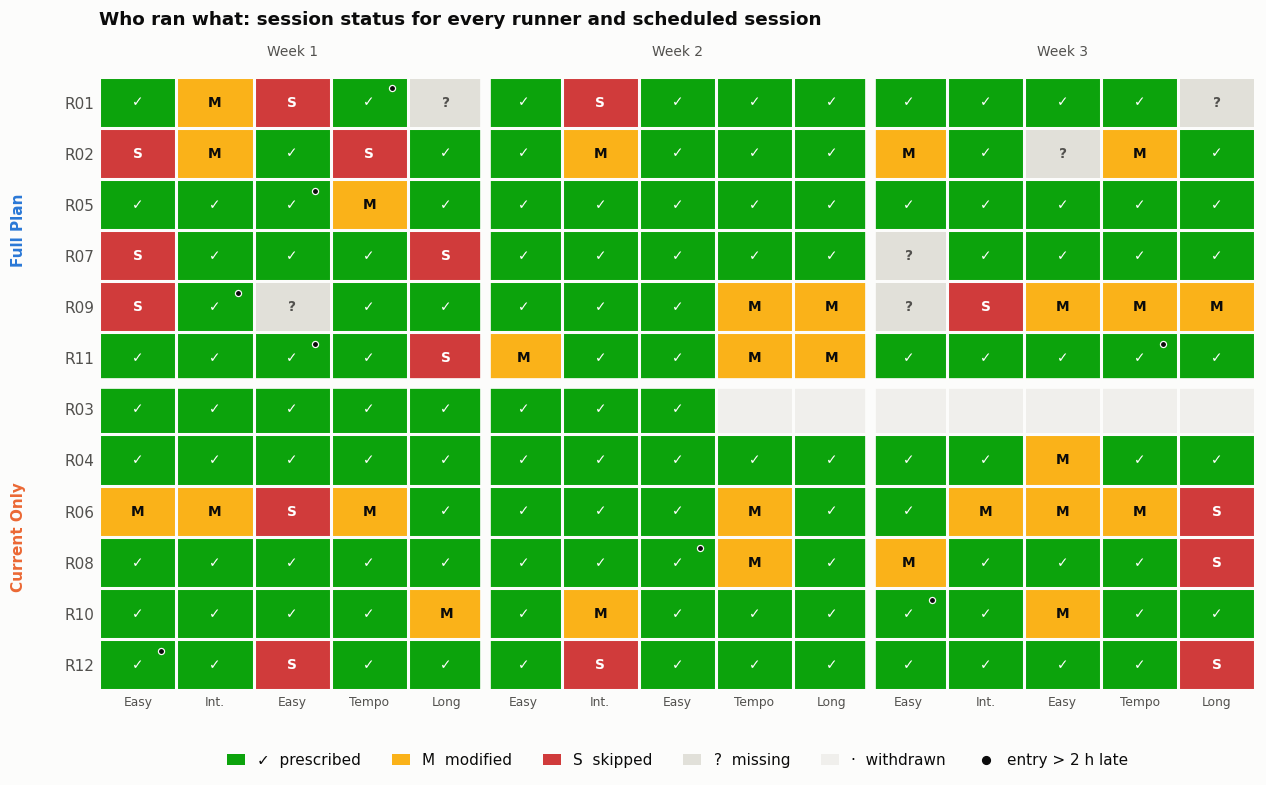

In [13]:
def plot_compliance_calendar(sessions):
    order = (sessions[["participant_code", "condition"]].drop_duplicates()
             .sort_values(["condition", "participant_code"]))
    codes = order["participant_code"].tolist()
    status_order = ["prescribed", "modified", "skipped", "missing", "withdrawn"]
    glyph = {"prescribed": "✓", "modified": "M", "skipped": "S", "missing": "?", "withdrawn": ""}
    glyph_color = {"prescribed": "white", "modified": INK, "skipped": "white", "missing": INK2, "withdrawn": INK2}
    mat = sessions.pivot(index="participant_code", columns="session_index", values="status").loc[codes].astype(str)
    late = sessions.pivot(index="participant_code", columns="session_index", values="flag_late").loc[codes]
    num = mat.apply(lambda c: c.map({s: i for i, s in enumerate(status_order)})).to_numpy(float)
    n_rows, n_cols = num.shape
    fig, ax = plt.subplots(figsize=(11.5, 0.42 * n_rows + 2.2))
    ax.imshow(num, cmap=ListedColormap([STATUS_COLORS[s] for s in status_order]), vmin=-0.5, vmax=4.5, aspect="auto")
    ax.set_xticks(np.arange(-.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_rows, 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for w in range(1, N_WEEKS):
        ax.axvline(w * SESSIONS_PER_WEEK - 0.5, color=SURFACE, lw=7)
    n_fp = int((order["condition"] == "Full Plan").sum())
    ax.axhline(n_fp - 0.5, color=SURFACE, lw=7)
    for i in range(n_rows):
        for j in range(n_cols):
            st = mat.iat[i, j]
            ax.text(j, i, glyph[st], ha="center", va="center", fontsize=9, color=glyph_color[st], fontweight="bold")
            if late.iat[i, j]:
                ax.plot(j + 0.3, i - 0.27, marker="o", ms=4, color=INK, mec=SURFACE, mew=0.8)
    short = {"Easy run": "Easy", "Interval run": "Int.", "Tempo run": "Tempo", "Long run": "Long"}
    ax.set_xticks(range(n_cols), [short[PLAN[k % SESSIONS_PER_WEEK]] for k in range(n_cols)], fontsize=8)
    ax.set_yticks(range(n_rows), codes)
    for w in range(N_WEEKS):
        ax.text(w * SESSIONS_PER_WEEK + 2, -0.85, f"Week {w + 1}", ha="center", va="bottom", color=INK2, fontsize=9)
    for cond, (lo, hi) in {"Full Plan": (0, n_fp - 1), "Current Only": (n_fp, n_rows - 1)}.items():
        ax.text(-1.55, (lo + hi) / 2, cond, rotation=90, ha="center", va="center", color=COND_COLORS[cond],
                fontweight="bold")
    for sp in ax.spines.values():
        sp.set_visible(False)
    handles = [Patch(facecolor=STATUS_COLORS[s], label=f"{glyph[s] or '·'}  {s}") for s in status_order]
    handles.append(Line2D([], [], marker="o", ls="", color=INK, ms=5, label="entry > 2 h late"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=6, handlelength=1.2)
    ax.set_title("Who ran what: session status for every runner and scheduled session", pad=34)
    fig.tight_layout()
    save_fig(fig, "fig01_compliance_calendar")
    return fig


plot_compliance_calendar(sessions);

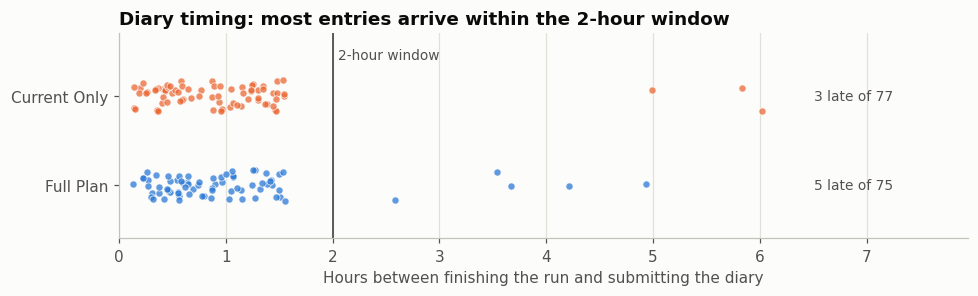

In [14]:
def plot_submission_lag(sessions):
    d = sessions[sessions["completed"]].dropna(subset=["submit_lag_h"])
    fig, ax = plt.subplots(figsize=(9, 2.8))
    g = np.random.default_rng(SEED)
    for k, cond in enumerate(CONDITIONS):
        v = d.loc[d["condition"] == cond, "submit_lag_h"]
        ax.scatter(v, k + g.uniform(-0.18, 0.18, len(v)), s=22, color=COND_COLORS[cond], alpha=0.75,
                   edgecolor=SURFACE, linewidth=0.6)
        ax.text(d["submit_lag_h"].max() * 1.08, k, f"{(v > LATE_THRESHOLD_H).sum()} late of {len(v)}",
                va="center", color=INK2, fontsize=9)
    ax.axvline(LATE_THRESHOLD_H, color=INK2, lw=1.2)
    ax.text(LATE_THRESHOLD_H + 0.05, 1.45, "2-hour window", color=INK2, fontsize=9, va="center")
    ax.set_yticks([0, 1], CONDITIONS)
    ax.set_ylim(-0.6, 1.7)
    ax.set_xlim(0, d["submit_lag_h"].max() * 1.32)
    ax.set_xlabel("Hours between finishing the run and submitting the diary")
    ax.grid(axis="y", visible=False)
    ax.set_title("Diary timing: most entries arrive within the 2-hour window")
    fig.tight_layout()
    save_fig(fig, "fig02_submission_lag")
    return fig


plot_submission_lag(sessions);

In [15]:
skips = sessions[sessions["status"] == "skipped"]
pd.crosstab(skips["skip_reason"], skips["condition"], margins=True, margins_name="Total")

condition,Full Plan,Current Only,Total
skip_reason,,,
Family event,1,0,1
Illness,3,0,3
Injury or soreness,0,2,2
Low motivation,2,1,3
Schedule conflict,1,2,3
Weather,2,1,3
Total,9,6,15


## 7. RQ1: Cognitive load (NASA-TLX)
**Primary analysis (descriptive, per the proposal):** each runner's average across completed sessions, summarized per condition. Mental demand is the main indicator of plan-related load.

In [16]:
TLX_LABELS = {"tlx_raw": "Raw TLX", "mental": "Mental demand", "tlx_physical_100": "Physical demand",
              "tlx_temporal_100": "Temporal demand", "tlx_performance_100": "Performance (0 = perfect)",
              "tlx_effort_100": "Effort", "tlx_frustration_100": "Frustration"}
pm_all = participant_means(sessions, ["rpe", *TLX_LABELS])
describe_by_condition(pm_all, list(TLX_LABELS), TLX_LABELS).round(1)

n runners  mean    SD  median   min   max
measure                   condition                                              
Raw TLX                   Full Plan             6  37.8   4.6    39.8  31.1  41.7
                          Current Only          6  28.6   2.7    28.5  25.6  32.4
Mental demand             Full Plan             6  46.2  10.8    43.8  32.7  65.0
                          Current Only          6  25.4   4.6    25.7  17.5  31.2
Physical demand           Full Plan             6  57.5   8.5    56.1  48.6  68.0
                          Current Only          6  47.5   6.0    49.3  37.5  53.3
Temporal demand           Full Plan             6  28.4  12.0    31.2  12.7  40.8
                          Current Only          6  16.3   4.7    17.6   7.1  20.8
Performance (0 = perfect) Full Plan             6  22.1   6.9    20.4  13.3  33.6
                          Current Only          6  22.9   4.2    22.4  17.5  29.2
Effort                    Full Plan             6  45.2   5.0    46.6  38.3  50.7
                          Current Only          6  39.7   5.1    41.6  31.2  45.3
Frustration               Full Plan             6  27.1  10.0    24.6  12.7  40.0
                          Current Only          6  20.1   7.3    19.6   8.6  30.0

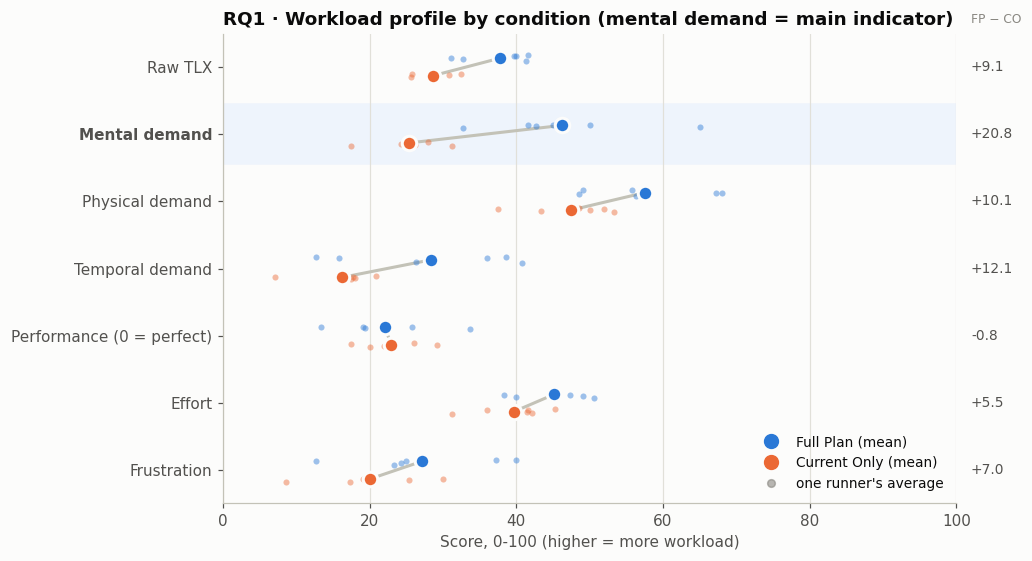

In [17]:
def plot_tlx_profile(pm):
    rows = list(TLX_LABELS)[::-1]
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    g = np.random.default_rng(SEED)
    for y, col in enumerate(rows):
        if col == "mental":
            ax.axhspan(y - 0.45, y + 0.45, color="#eef4fc", zorder=0)
        means = {}
        for k, cond in enumerate(CONDITIONS):
            v = pm.loc[pm["condition"] == cond, col].dropna()
            off = 0.13 if k == 0 else -0.13
            ax.scatter(v, y + off + g.uniform(-0.05, 0.05, len(v)), s=16, color=COND_COLORS[cond], alpha=0.45,
                       linewidth=0, zorder=2)
            means[cond] = (v.mean(), y + off)
        (x1, y1), (x2, y2) = means["Full Plan"], means["Current Only"]
        ax.plot([x1, x2], [y1, y2], color=AXIS, lw=2, zorder=1)
        for cond, (x, yy) in means.items():
            ax.scatter(x, yy, s=90, color=COND_COLORS[cond], edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.text(102, y, f"{x1 - x2:+.1f}", va="center", ha="left", color=INK2, fontsize=9)
    ax.text(102, len(rows) - 0.35, "FP − CO", ha="left", color=MUTED, fontsize=8)
    ax.set_yticks(range(len(rows)), [TLX_LABELS[r] for r in rows])
    ax.get_yticklabels()[rows.index("mental")].set_fontweight("bold")
    ax.set_xlim(0, 100)
    ax.set_xlabel("Score, 0-100 (higher = more workload)")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color=COND_COLORS[c], label=f"{c} (mean)") for c in CONDITIONS]
              + [Line2D([], [], marker="o", ls="", ms=5, color=MUTED, alpha=.6, label="one runner's average")],
              loc="lower right", fontsize=9)
    ax.set_title("RQ1 · Workload profile by condition (mental demand = main indicator)")
    fig.tight_layout()
    save_fig(fig, "fig03_tlx_profile")
    return fig


plot_tlx_profile(pm_all);

**Mental demand by session type.** If Full Plan runners carry more plan-related load, the gap should appear across session types, not only on complex sessions such as intervals.

In [18]:
by_type = (sessions[sessions["completed"]]
           .groupby(["participant_code", "condition", "session_type"], observed=True)["mental"].mean().reset_index()
           .groupby(["session_type", "condition"], observed=True)["mental"].agg(["mean", "std", "count"]).round(1)
           .unstack("condition"))
by_type.columns = [f"{stat} · {cond}" for stat, cond in by_type.columns]
by_type

,mean · Full Plan,mean · Current Only,std · Full Plan,std · Current Only,count · Full Plan,count · Current Only
session_type,,,,,,
Easy run,37.4,20.4,11.6,3.6,6,6
Interval run,61.9,33.1,11.6,9.2,6,6
Tempo run,46.9,28.3,10.2,4.6,6,6
Long run,45.3,24.2,9.8,4.9,6,6


## 8. RQ2: Perceived exertion (Borg RPE)

This section contains the summary statistics for the Borg Rating of Perceived Excertion (Borg RPE) and the statistical analysis to determine:

- How does the pacing of exercise disclosure affect runners' rate of perceived exertion (RPE) during a structured run?

A Linear Mixed Model (LMM) is used to to measure how a workout plan's disclosure method `(condition)`, session type `(session_type)`, running experience `(experience_group)`, and time `(session_index)` affect the runner's perceived exertion `(rpe)`, while accounting for repeated measurements from the same participant using `(participant_code)`.

### Summary Statistics for Borg RPE, grouped by disclosure method


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def plot_summary_statistics(df):
    # Create figure with 2 side-by-side subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Box & Whisker Plot (Updated for Seaborn >= 0.13)
    sns.boxplot(
        data=df,
        x="condition",
        y="rpe",
        hue="condition",  # Assign hue to match x variable
        palette="Set2",
        legend=False,  # Prevents redundant legend boxplot key
        showmeans=True,  # Shows mean as a distinct marker alongside median
        meanprops={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
        },
        ax=axes[0],
    )
    axes[0].set_title("RPE Distribution by Condition", fontsize=12)
    axes[0].set_xlabel("Condition", fontsize=10)
    axes[0].set_ylabel("RPE", fontsize=10)

    # 2. Histogram with Kernel Density Estimate (shows Skewness)
    sns.histplot(
        data=df,
        x="rpe",
        hue="condition",
        kde=True,
        element="step",
        common_norm=False,
        palette="Set2",
        ax=axes[1],
    )
    axes[1].set_title("RPE Skewness & Frequency Histogram", fontsize=12)
    axes[1].set_xlabel("RPE", fontsize=10)
    axes[1].set_ylabel("Count", fontsize=10)

    plt.tight_layout()
    plt.show()

### Summary Statistics for an Individual Runner's average RPE across their completed sessions

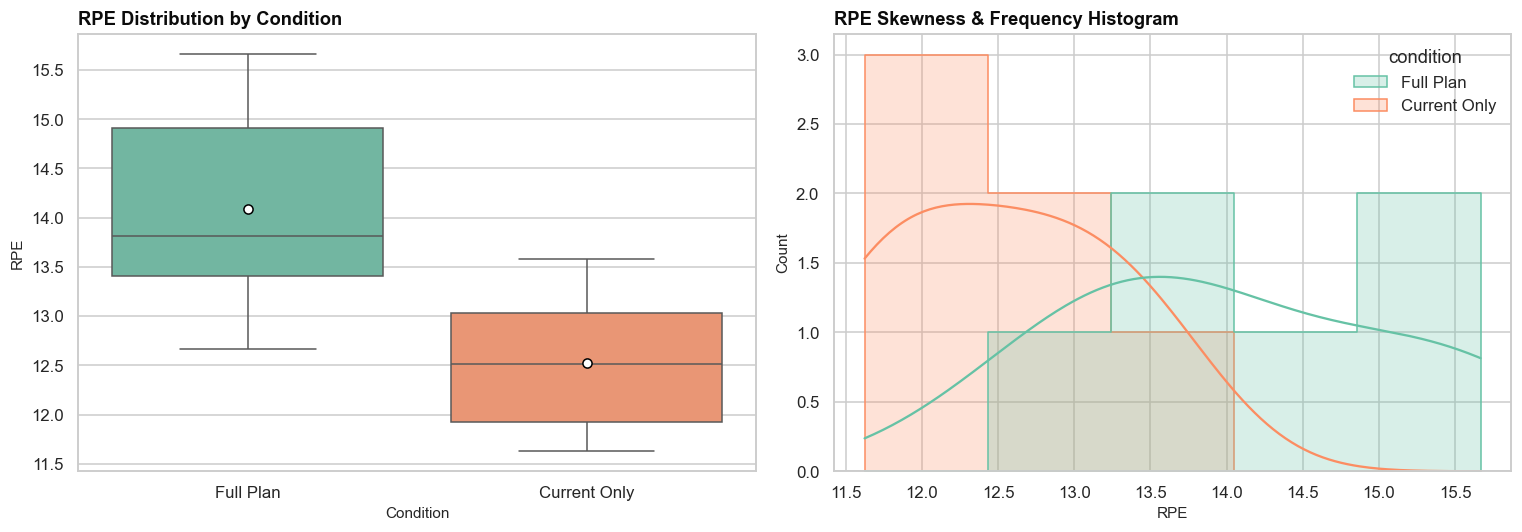

n runners   mean    SD  median    min    max
measure         condition                                                 
Borg RPE (6-20) Full Plan             6  14.08  1.14   13.81  12.67  15.67
                Current Only          6  12.53  0.76   12.51  11.62  13.58

In [21]:
plot_summary_statistics(pm_all)
describe_by_condition(pm_all, ["rpe"], {"rpe": "Borg RPE (6-20)"}).round(2)


### Summary Statistics for RPE by condition

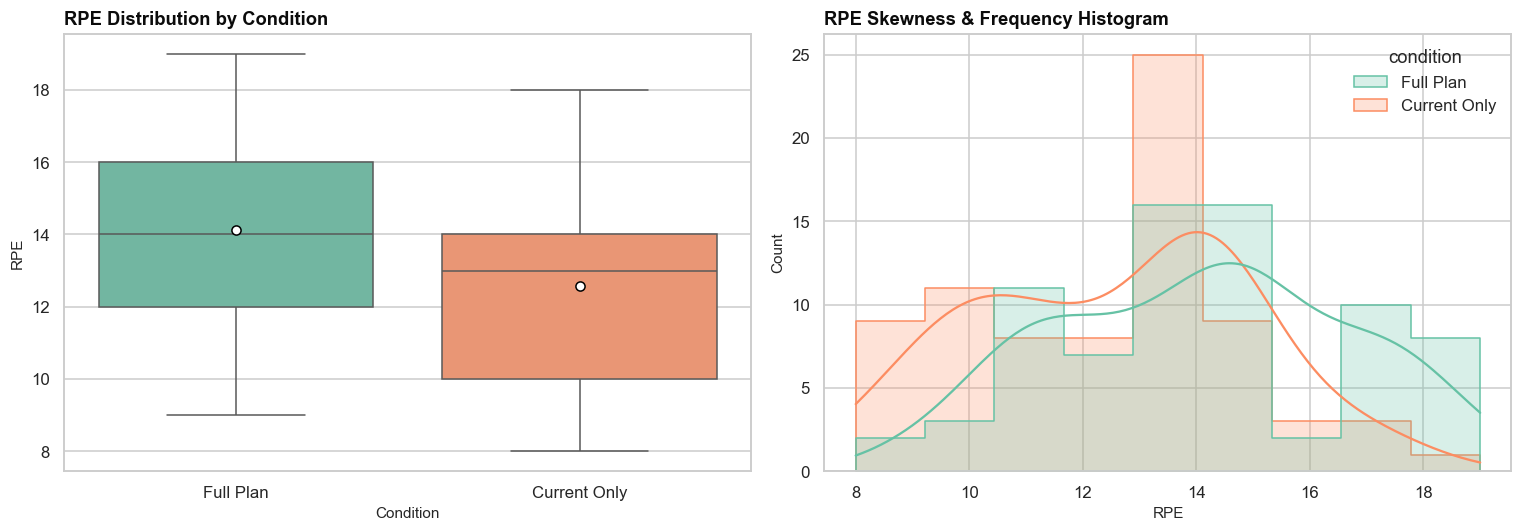

,condition,Count,Missing,Missing_%,Mean,Std,Min,Q25,Median,Q75,Max,IQR,Skewness
0,Current Only,77,13.0,14.444444,12.571429,2.435638,8.0,10.0,13.0,14.0,18.0,4.0,-0.049799
1,Full Plan,75,15.0,16.666667,14.12,2.573041,9.0,12.0,14.0,16.0,19.0,4.0,-0.033824


In [22]:
# 1. Merge key dataframe into clean_df on participant_code
key["participant_code"] = key["participant_code"].astype(str).str.strip()
clean_df["participant_code"] = clean_df["participant_code"].astype(str).str.strip()

rpe_df = clean_df.merge(
    key[["participant_code", "condition", "experience_group"]],
    on="participant_code",
    how="left",
)

# 2. Compute summary statistics using named aggregation
summary_stats = (
    rpe_df.groupby("condition")["rpe"]
    .agg(
        Count="count",
        Missing=lambda x: x.isna().sum(),
        Missing_pct=lambda x: (x.isna().sum() / len(x)) * 100,
        Mean="mean",
        Std="std",
        Min="min",
        Q25=lambda x: x.quantile(0.25),
        Median="median",
        Q75=lambda x: x.quantile(0.75),
        Max="max",
        IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
        Skewness="skew",
    )
    .reset_index()
    .rename(columns={"Missing_pct": "Missing_%"})
)

plot_summary_statistics(rpe_df)
display(summary_stats)

### Summary Statistics for RPE by condition, faceted by session type

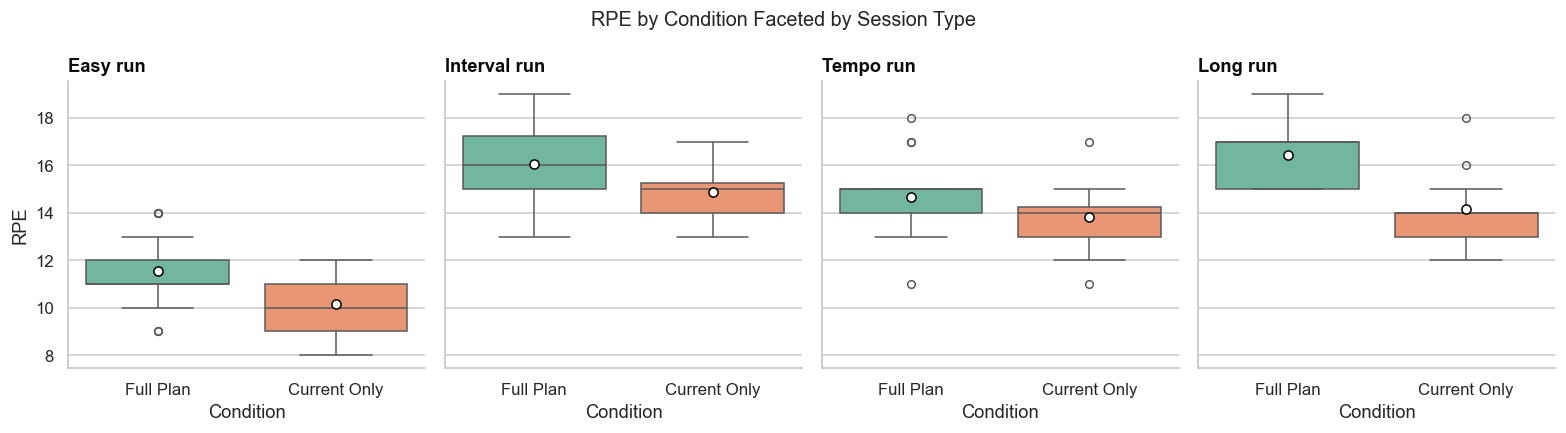

In [25]:
# Stratify by session_type and condition simultaneously
session_sensitivity = (
    rpe_df.groupby(["session_type", "condition"])["rpe"]
    .agg(Count="count", Mean="mean", Std="std", Median="median")
    .reset_index()
)

# Faceted Boxplot Grid
g = sns.catplot(
    data=rpe_df,
    x="condition",
    y="rpe",
    col="session_type",
    hue="condition",  # Set hue equal to x to prevent warning
    kind="box",
    palette="Set2",
    legend=False,
    height=4,
    aspect=0.9,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
    },
)

g.set_axis_labels("Condition", "RPE")
g.set_titles(col_template="{col_name}")
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("RPE by Condition Faceted by Session Type", fontsize=13)

plt.show()

### Linear Mixed Models

Linear Mixed Models (LMMs) is used to measure how a workout plan's disclosure method `(condition)`, workout type `(session_type)`, running experience `(experience_group)`, and time `(session_index)` affect the runner's perceived exertion `(rpe)`, while accounting for repeated measurements from the same participant using `participant_code`.

| Model Object | Formula | What It Measures | Relevance |
|---|---|---|---|
| `fit_main` | `rpe ~ C(condition) + C(session_type) + C(experience_group)` |  The individual association of condition, workout type, and running experience with RPE, accounting for the other predictors. | "Does Full Plan change RPE overall, accounting for workout type and running experience?" |
| `fit_session` | `rpe ~ C(condition) * C(session_type) + C(experience_group)` | Whether the association between condition and RPE varies depending on workout type. | "Does Full Plan affect RPE differently depending on workout type?" |
| `fit_experience` | `rpe ~ C(condition) * C(experience_group) + C(session_type)` | Whether the association between condition and RPE varies depending on experience group. | "Does Full Plan affect RPE differently depending on participants' experience level?" |
| `fit_time` | `rpe ~ C(condition) * session_index + C(session_type) + C(experience_group)` | Whether the difference in RPE between conditions changes across successive sessions (condition-specific time trend). | "Does the relationship between training condition and RPE change over the 15 sessions?" |



The following variables are used as the baseline for their respective columns:

- `condition`: "Current Only"
- `experience_group`: "Advanced"
- `session_type`: "Easy Run"

Meanwhile, `session_index` is numerical. This value ranges from 1 to N, where N is the number of sessions required in the study. Each runner has its own session index, ordered by date. Not all sessions are guaranteed to have a value for its `rpe`.

=================== PRIMARY LMM RESULTS ===================
                  Mixed Linear Model Regression Results
Model:                  MixedLM       Dependent Variable:       rpe      
No. Observations:       152           Method:                   REML     
No. Groups:             12            Scale:                    1.2966   
Min. group size:        8             Log-Likelihood:           -245.1597
Max. group size:        15            Converged:                Yes      
Mean group size:        12.7                                             
-------------------------------------------------------------------------
                                Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------------
Intercept                       9.642    0.416 23.190 0.000  8.827 10.457
C(condition)[T.Full Plan]       1.346    0.466  2.892 0.004  0.434  2.259
C(session_type)[T.Interval run] 4.689    0.250 18.771 0.000  4.200  5.

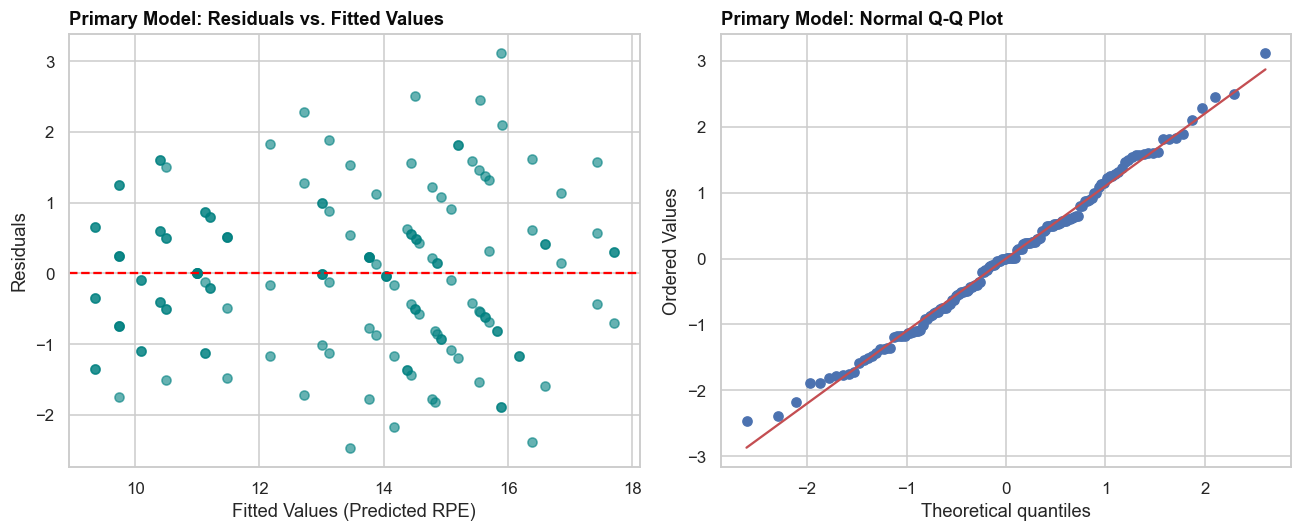

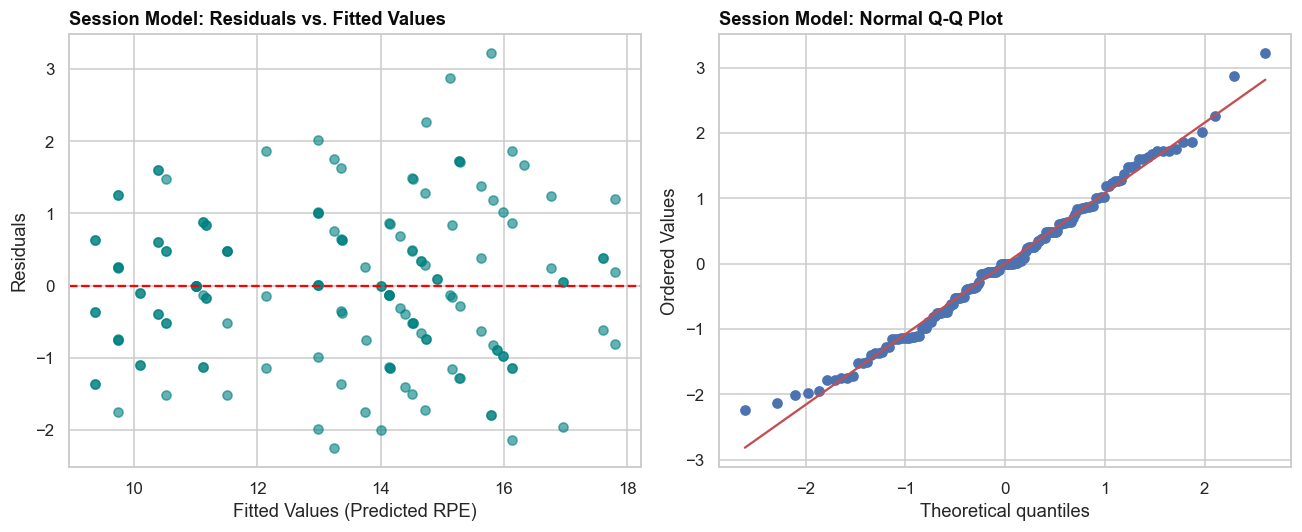

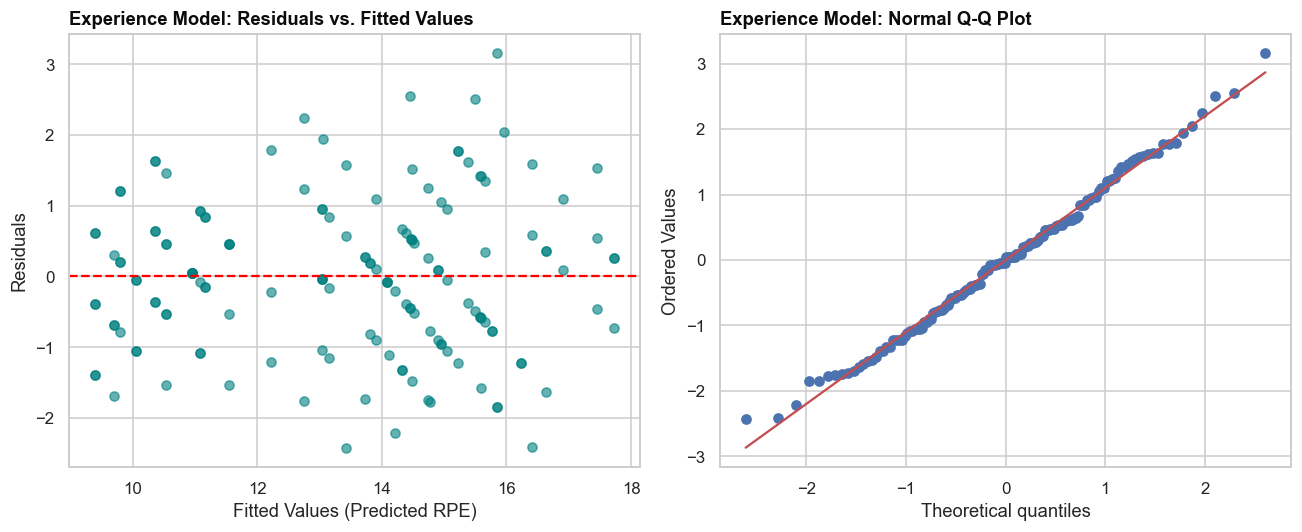

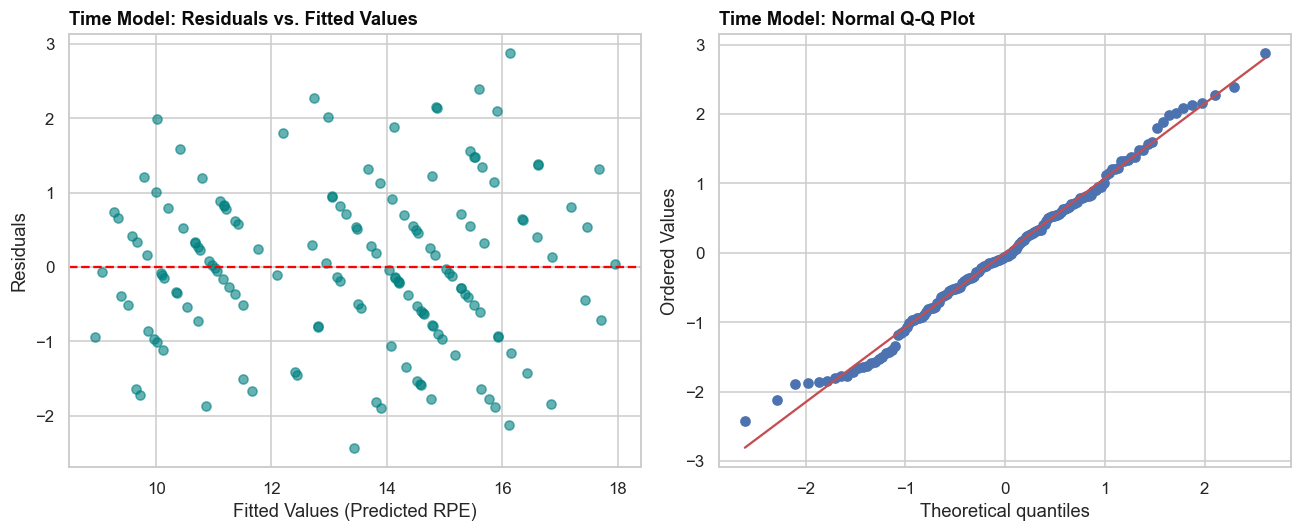

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Prepare dataframe
analysis_df = rpe_df.dropna(subset=["rpe"]).copy()
analysis_df["condition"] = pd.Categorical(
    analysis_df["condition"], categories=["Current Only", "Full Plan"]
)

# 2. Create LMMs
# Primary Model
# Formula: RPE ~ condition + session_type + experience_group
# Random Intercept: grouped by participant_code
lmm_main = smf.mixedlm(
    formula="rpe ~ C(condition) + C(session_type) + C(experience_group)",
    data=analysis_df,
    groups=analysis_df["participant_code"],
)

fit_main = lmm_main.fit(reml=True)
print("=================== PRIMARY LMM RESULTS ===================")
print(fit_main.summary())

# Extract Fixed Effects Table with 95% Confidence Intervals
fixed_effects = pd.DataFrame(
    {
        "Coefficient": fit_main.params,
        "Std Error": fit_main.bse,
        "z value": fit_main.tvalues,
        "p value": fit_main.pvalues,
        "CI Lower": fit_main.conf_int()[0],
        "CI Upper": fit_main.conf_int()[1],
    }
)
print("\n=== FIXED EFFECTS TABLE ===")
print(fixed_effects.round(4))

# Session Model: if disclosure impact depends on workout type or runner experience
lmm_session = smf.mixedlm(
    formula="rpe ~ C(condition) * C(session_type) + C(experience_group)",
    data=analysis_df,
    groups=analysis_df["participant_code"],
)
fit_session = lmm_session.fit(reml=True)

print("\n=================== SESSION LMM RESULTS ===================")
print(fit_session.summary())

# Experience Model: if disclosure impact depends on workout type or runner experience
lmm_experience = smf.mixedlm(
    formula="rpe ~ C(condition) * C(experience_group) + C(session_type)",
    data=analysis_df,
    groups=analysis_df["participant_code"],
)
fit_experience = lmm_experience.fit(reml=True)

print("\n=================== SESSION LMM RESULTS ===================")
print(fit_experience.summary())


# Time Model: Condition x Session Index (Time): if exertion differences change across the 15 sessions over time
lmm_time = smf.mixedlm(
    formula="rpe ~ C(condition) * session_index + C(session_type) + C(experience_group)",
    data=analysis_df,
    groups=analysis_df["participant_code"],
)
fit_time = lmm_time.fit(reml=True)

print("\n=================== TIME LMM RESULTS ===================")
print(fit_time.summary())

# 3. Residual Diagnostics & Assumption Checks
def plot_model_values(fitted_values, residuals, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Residuals vs Fitted
    axes[0].scatter(fitted_values, residuals, alpha=0.6, color="teal")
    axes[0].axhline(0, color="red", linestyle="--", linewidth=1.5)
    axes[0].set_title(f"{title}: Residuals vs. Fitted Values")
    axes[0].set_xlabel("Fitted Values (Predicted RPE)")
    axes[0].set_ylabel("Residuals")

    # Q-Q Plot
    stats.probplot(residuals, dist="norm", plot=axes[1])
    axes[1].set_title(f"{title}: Normal Q-Q Plot")

    plt.tight_layout()
    plt.show()

models = {
    "Primary Model": fit_main,
    "Session Model": fit_session,
    "Experience Model": fit_experience,
    "Time Model": fit_time
}

for name, model in models.items():
    plot_model_values(model.fittedvalues, model.resid, title=name)

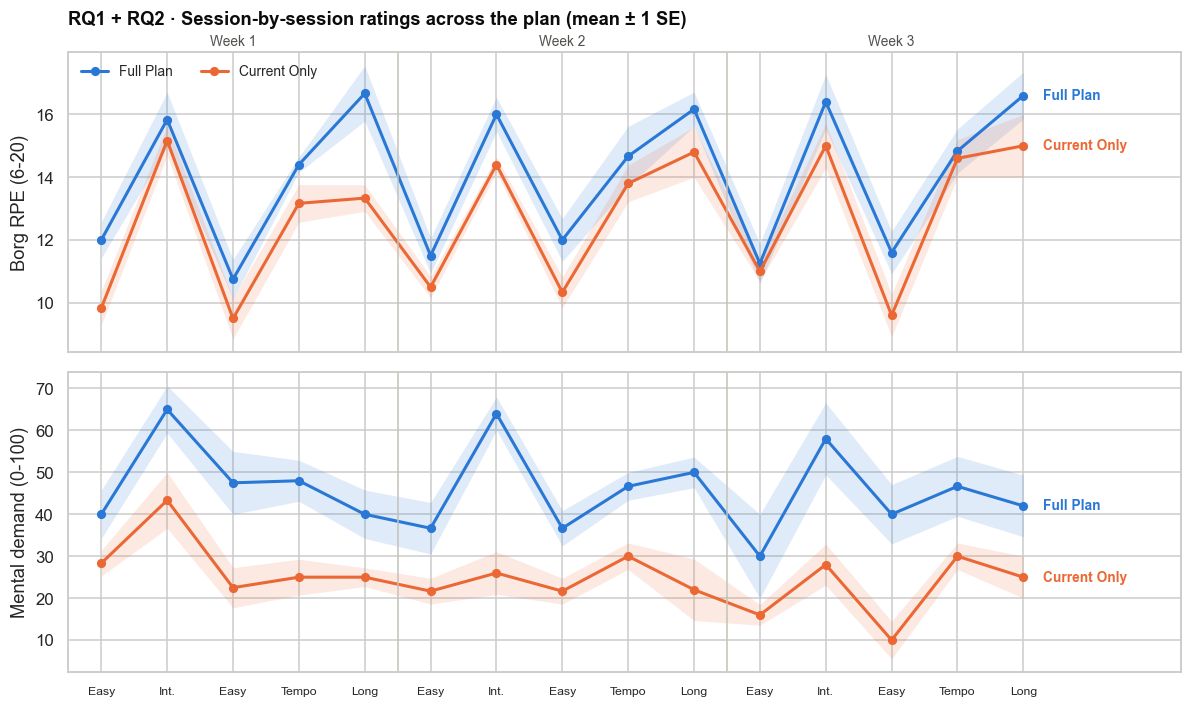

In [27]:
def plot_trajectories(sessions):
    d = sessions[sessions["completed"]]
    panels = [("rpe", "Borg RPE (6-20)"), ("mental", "Mental demand (0-100)")]
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True)
    n = N_WEEKS * SESSIONS_PER_WEEK
    for ax, (col, label) in zip(axes, panels):
        for cond in CONDITIONS:
            g = d[d["condition"] == cond].groupby("session_index")[col]
            m, se = g.mean(), g.std() / np.sqrt(g.count())
            ax.fill_between(m.index.astype(float), m - se, m + se, color=COND_COLORS[cond], alpha=0.14, lw=0)
            ax.plot(m.index.astype(float), m, color=COND_COLORS[cond], lw=2, marker="o", ms=5, label=cond)
            ax.text(n + 0.3, m.iloc[-1], cond, color=COND_COLORS[cond], va="center", fontsize=9, fontweight="bold")
        for w in range(1, N_WEEKS):
            ax.axvline(w * SESSIONS_PER_WEEK + 0.5, color=AXIS, lw=1)
        ax.set_ylabel(label)
        ax.set_xlim(0.5, n + 2.4)
    short = {"Easy run": "Easy", "Interval run": "Int.", "Tempo run": "Tempo", "Long run": "Long"}
    axes[1].set_xticks(range(1, n + 1), [f"{short[PLAN[(k - 1) % 5]]}" for k in range(1, n + 1)], fontsize=8)
    for w in range(N_WEEKS):
        axes[0].text(w * SESSIONS_PER_WEEK + 3, 1.02, f"Week {w + 1}", transform=axes[0].get_xaxis_transform(),
                     ha="center", color=INK2, fontsize=9)
    axes[0].legend(loc="upper left", ncol=2, fontsize=9)
    axes[0].set_title("RQ1 + RQ2 · Session-by-session ratings across the plan (mean ± 1 SE)", pad=18)
    fig.tight_layout()
    save_fig(fig, "fig04_trajectories")
    return fig


plot_trajectories(sessions);

### Estimation plots (Gardner-Altman)
Instead of a bar chart with a p-value, each panel shows **every runner's average** (left) and the **difference between conditions with its bootstrap 95% CI** (right; the shaded shape is the bootstrap distribution). This shows both the size of the gap and how uncertain it is with six runners per group.

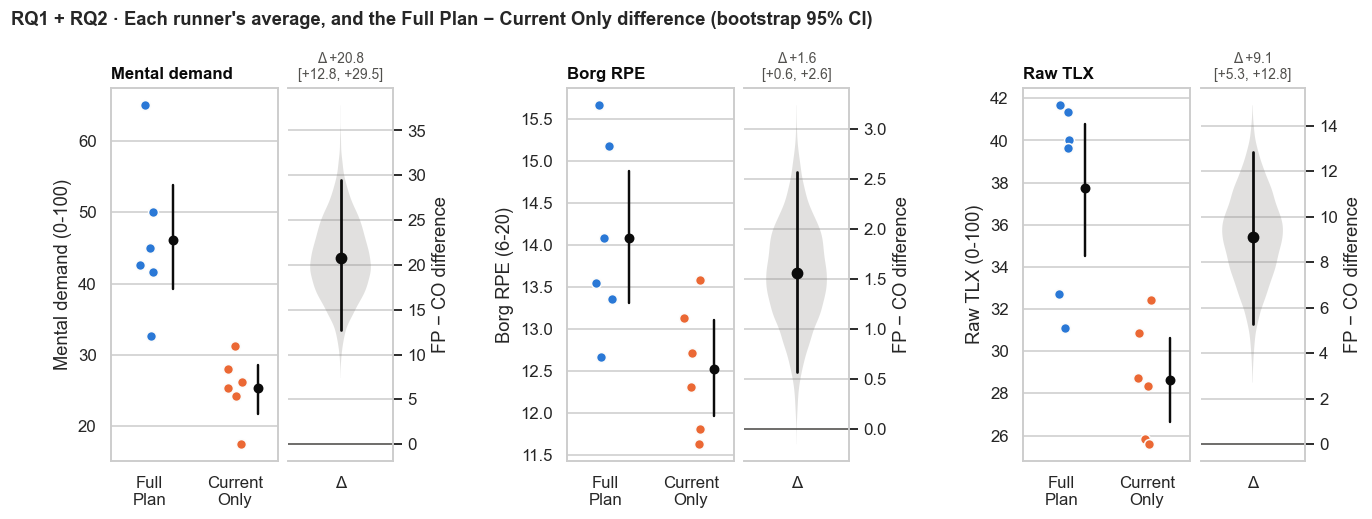

In [28]:
def plot_estimation(pm, outcomes):
    fig = plt.figure(figsize=(14, 4.4))
    outer = fig.add_gridspec(1, len(outcomes), wspace=0.62)
    g = np.random.default_rng(SEED)
    results = {}
    for k, (col, label) in enumerate(outcomes.items()):
        inner = outer[k].subgridspec(1, 2, width_ratios=[1.6, 1], wspace=0.08)
        ax, axd = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
        res = bootstrap_diff(pm, col)
        results[col] = res
        for i, cond in enumerate(CONDITIONS):
            v = pm.loc[pm["condition"] == cond, col].dropna().to_numpy()
            ax.scatter(i + g.uniform(-0.12, 0.12, len(v)), v, s=42, color=COND_COLORS[cond], edgecolor=SURFACE,
                       linewidth=1, zorder=3)
            boots = [g.choice(v, len(v)).mean() for _ in range(2000)]
            lo, hi = np.percentile(boots, [2.5, 97.5])
            ax.plot([i + 0.27] * 2, [lo, hi], color=INK, lw=1.6)
            ax.scatter(i + 0.27, v.mean(), s=30, color=INK, zorder=4)
        ax.set_xticks([0, 1], ["Full\nPlan", "Current\nOnly"])
        ax.set_xlim(-0.45, 1.5)
        ax.set_ylabel(label)
        ax.grid(axis="x", visible=False)
        ax.set_title(label.split(" (")[0], fontsize=11)
        parts = axd.violinplot(res["boot"], positions=[0], widths=0.7, showextrema=False)
        for b in parts["bodies"]:
            b.set_facecolor(MUTED); b.set_alpha(0.25); b.set_edgecolor("none")
        axd.plot([0, 0], [res["diff_lo"], res["diff_hi"]], color=INK, lw=1.8)
        axd.scatter(0, res["diff"], s=45, color=INK, zorder=3)
        axd.axhline(0, color=INK2, lw=1)
        axd.yaxis.tick_right(); axd.yaxis.set_label_position("right")
        axd.spines["right"].set_visible(True); axd.spines["left"].set_visible(False)
        axd.set_ylabel("FP − CO difference")
        axd.set_xticks([0], ["Δ"])
        axd.set_xlim(-0.6, 0.6)
        axd.grid(axis="x", visible=False)
        axd.set_title(f"Δ {res['diff']:+.1f}\n[{res['diff_lo']:+.1f}, {res['diff_hi']:+.1f}]", fontsize=9,
                      fontweight="normal", color=INK2, loc="center")
    fig.suptitle("RQ1 + RQ2 · Each runner's average, and the Full Plan − Current Only difference (bootstrap 95% CI)",
                 x=0.06, ha="left", fontweight="bold", fontsize=12, y=1.04)
    save_fig(fig, "fig05_estimation_plots")
    return fig, results


_, est_results = plot_estimation(pm_all, OUTCOMES)

### Anticipatory pacing: does knowing what comes next change effort?
Anticipatory regulation (Tucker, 2009) predicts that runners who **can see** the next session adjust today's effort: holding back before a harder session, pushing before an easy one or on the final session. Current Only runners cannot see ahead, so their pattern should be flat.

To isolate this, each rating is adjusted for the runner's usual level and the session type's usual level (`rpe_adj`, `mental_adj`), so what remains is "harder or easier than expected for this runner on this kind of session". Dots are runner averages; bars are 95% CIs across runners.

condition                       Current Only  Full Plan
measure    next                                        
mental_adj easy run next               -2.27       3.82
           final session               -0.36      -4.99
           harder session next          1.28      -1.68
rpe_adj    easy run next               -0.18       0.05
           final session                0.62       0.69
           harder session next          0.08      -0.08

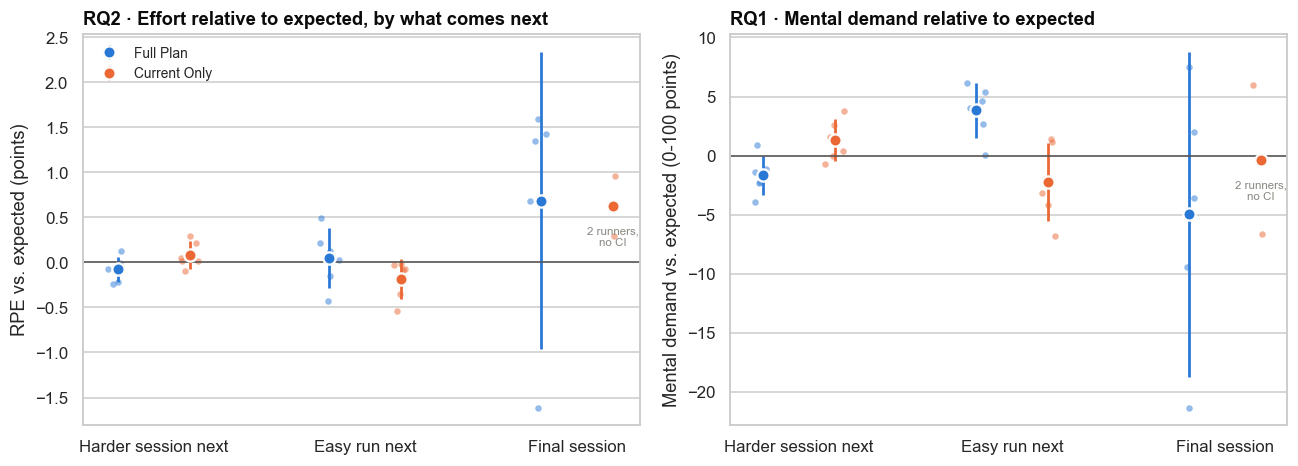

In [29]:
def plot_anticipatory(sessions):
    d = sessions[sessions["completed"]]
    cats = list(d["next_category"].cat.categories)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=False)
    g = np.random.default_rng(SEED)
    out = []
    for ax, (col, label) in zip(axes, [("rpe_adj", "RPE vs. expected (points)"), ("mental_adj", "Mental demand vs. expected (0-100 points)")]):
        rm = d.groupby(["participant_code", "condition", "next_category"], observed=True)[col].mean().reset_index()
        for k, cond in enumerate(CONDITIONS):
            off = -0.17 if k == 0 else 0.17
            for i, cat in enumerate(cats):
                v = rm.loc[(rm["condition"] == cond) & (rm["next_category"] == cat), col].dropna()
                if len(v) == 0:
                    continue
                ax.scatter(i + off + g.uniform(-0.05, 0.05, len(v)), v, s=18, color=COND_COLORS[cond], alpha=0.5, lw=0)
                # a CI from fewer than 3 runners is too wide to be informative, so it is not drawn
                half = stats.t.ppf(0.975, len(v) - 1) * v.std() / np.sqrt(len(v)) if len(v) >= 3 else np.nan
                ax.errorbar(i + off, v.mean(), yerr=None if np.isnan(half) else half, fmt="o", ms=8,
                            color=COND_COLORS[cond], mec=SURFACE, mew=1.5, elinewidth=1.8, capsize=0,
                            label=cond if i == 0 else None)
                if len(v) < 3:
                    ax.annotate(f"{len(v)} runners,\nno CI", (i + off, v.mean()), xytext=(0, -26),
                                textcoords="offset points", ha="center", fontsize=7.5, color=MUTED)
                out.append(dict(measure=col, condition=cond, next=cat, mean=v.mean(), ci=half, runners=len(v)))
        ax.axhline(0, color=INK2, lw=1)
        ax.set_xticks(range(len(cats)), [c.capitalize() for c in cats])
        ax.set_ylabel(label)
        ax.grid(axis="x", visible=False)
    axes[0].legend(loc="upper left", fontsize=9)
    axes[0].set_title("RQ2 · Effort relative to expected, by what comes next")
    axes[1].set_title("RQ1 · Mental demand relative to expected")
    fig.tight_layout()
    save_fig(fig, "fig06_anticipatory_pacing")
    return fig, pd.DataFrame(out)


_, anticip = plot_anticipatory(sessions)
anticip.pivot_table(index=["measure", "next"], columns="condition", values="mean", observed=True).round(2)

### Exploratory inferential checks
Not part of the planned descriptive analysis and **not confirmatory** (n = 12). They show whether the descriptive differences are larger than what random assignment alone would produce, and whether the mixed model (using every session) agrees with the runner-level comparison.

In [30]:
rows = []
for col, label in OUTCOMES.items():
    perm = stratified_permutation_test(pm_all, col)
    est = est_results[col]
    mm = fit_mixed(sessions, col)
    rows.append({"outcome": label,
                 "Full Plan mean": pm_all.loc[pm_all.condition == "Full Plan", col].mean(),
                 "Current Only mean": pm_all.loc[pm_all.condition == "Current Only", col].mean(),
                 "difference [95% CI]": f"{est['diff']:+.2f} [{est['diff_lo']:+.2f}, {est['diff_hi']:+.2f}]",
                 "Hedges g [95% CI]": f"{est['g']:.2f} [{est['g_lo']:.2f}, {est['g_hi']:.2f}]",
                 "permutation p": perm["p"], "assignments": perm["n_assignments"],
                 "mixed model FP effect [95% CI]": f"{mm['estimate']:+.2f} [{mm['ci_lo']:+.2f}, {mm['ci_hi']:+.2f}]",
                 "mixed model p": mm["p"]})
inferential = pd.DataFrame(rows)
inferential.insert(inferential.columns.get_loc("assignments"), "Holm-adjusted p", holm(inferential["permutation p"]))
inferential.round(3)

,outcome,Full Plan mean,Current Only mean,difference [95% CI],Hedges g [95% CI],permutation p,Holm-adjusted p,assignments,mixed model FP effect [95% CI],mixed model p
0,Mental demand (0-100),46.177,25.420,"+20.76 [+12.78, +29.47]","2.31 [1.63, 5.51]",0.005,0.015,400,"+21.04 [+12.03, +30.04]",0.000
1,Borg RPE (6-20),14.084,12.527,"+1.56 [+0.57, +2.57]","1.48 [0.68, 3.06]",0.020,0.020,400,"+1.29 [+0.41, +2.18]",0.004
2,Raw TLX (0-100),37.752,28.639,"+9.11 [+5.29, +12.83]","2.22 [1.28, 6.94]",0.010,0.020,400,"+8.54 [+4.35, +12.72]",0.000


## 9. RQ3: Cognitive load and perceived exertion
Mental demand is used instead of overall TLX, because the physical demand and effort subscales overlap with RPE by definition. The relationship is looked at on **two levels that answer different questions**:

* **Within runners** (repeated-measures correlation): on sessions where a runner's mental demand is higher than *their own* usual, is their RPE also higher?
* **Between runners** (Spearman on averages): do runners with higher average mental demand report higher average RPE?

The proposal's session-level Spearman is also shown, with the caveat that it treats repeated sessions from one runner as independent.

In [31]:
done = sessions[sessions["completed"]]
corr_rows = []
for scope in ["All runners", *CONDITIONS]:
    d = done if scope == "All runners" else done[done["condition"] == scope]
    pmd = pm_all if scope == "All runners" else pm_all[pm_all["condition"] == scope]
    rm = rmcorr(d, "mental", "rpe")
    lo, hi = rmcorr_boot_ci(d, "mental", "rpe")
    b = stats.spearmanr(pmd["mental"], pmd["rpe"])
    sl = stats.spearmanr(d["mental"], d["rpe"], nan_policy="omit")
    corr_rows.append({"scope": scope,
                      "within-runner r_rm [95% CI]": f"{rm['r']:.2f} [{lo:.2f}, {hi:.2f}]", "r_rm df": rm["dof"],
                      "between-runner Spearman rho": round(b.statistic, 2), "runners": len(pmd),
                      "session-level Spearman rho (proposal)": round(sl.statistic, 2), "sessions": rm["n_obs"]})
pd.DataFrame(corr_rows)

,scope,within-runner r_rm [95% CI],r_rm df,between-runner Spearman rho,runners,session-level Spearman rho (proposal),sessions
0,All runners,"0.41 [0.32, 0.50]",139,0.38,12,0.40,152
1,Full Plan,"0.42 [0.28, 0.57]",68,-0.20,6,0.26,75
2,Current Only,"0.40 [0.29, 0.50]",70,-0.60,6,0.26,77


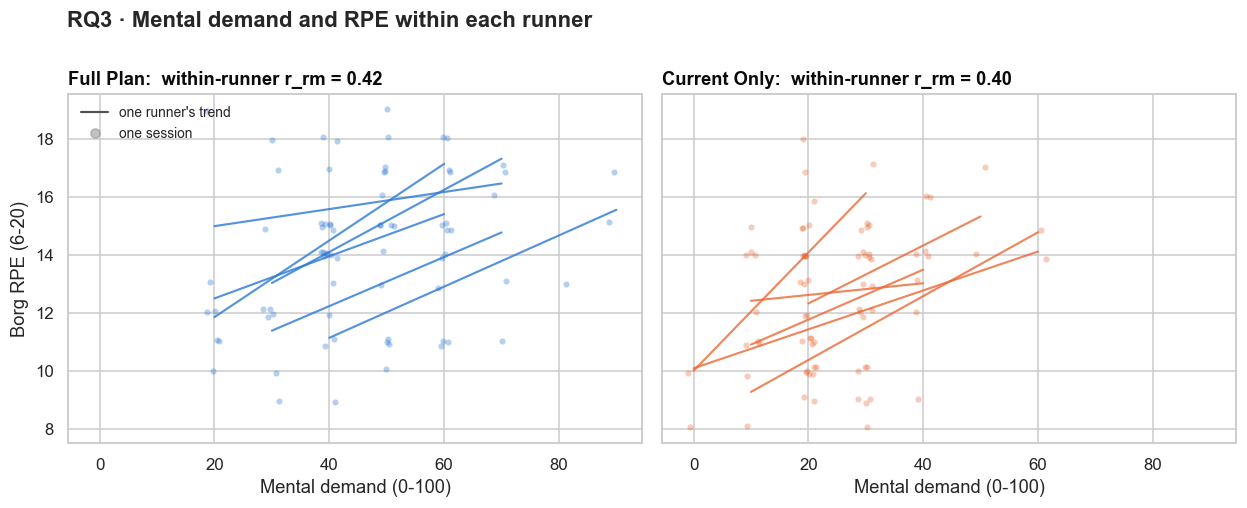

In [32]:
def plot_rq3(sessions):
    d = sessions[sessions["completed"]].dropna(subset=["mental", "rpe"])
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)
    g = np.random.default_rng(SEED)
    for ax, cond in zip(axes, CONDITIONS):
        dc = d[d["condition"] == cond]
        ax.scatter(dc["mental"] + g.uniform(-1.5, 1.5, len(dc)), dc["rpe"] + g.uniform(-0.15, 0.15, len(dc)),
                   s=16, color=COND_COLORS[cond], alpha=0.35, lw=0)
        for _, grp in dc.groupby("participant_code"):
            if grp["mental"].nunique() < 2:
                continue
            b1, b0 = np.polyfit(grp["mental"], grp["rpe"], 1)
            xs = np.array([grp["mental"].min(), grp["mental"].max()])
            ax.plot(xs, b0 + b1 * xs, color=COND_COLORS[cond], lw=1.4, alpha=0.8)
        rm = rmcorr(dc, "mental", "rpe")
        ax.set_title(f"{cond}:  within-runner r_rm = {rm['r']:.2f}", color=INK)
        ax.set_xlabel("Mental demand (0-100)")
    axes[0].set_ylabel("Borg RPE (6-20)")
    axes[0].legend(handles=[Line2D([], [], color=INK2, lw=1.4, label="one runner's trend"),
                            Line2D([], [], marker="o", ls="", color=MUTED, alpha=.5, label="one session")],
                   loc="upper left", fontsize=9)
    fig.suptitle("RQ3 · Mental demand and RPE within each runner", x=0.06, ha="left", fontweight="bold", y=1.0)
    fig.tight_layout()
    save_fig(fig, "fig07_rq3_within_runner")
    return fig


plot_rq3(sessions);

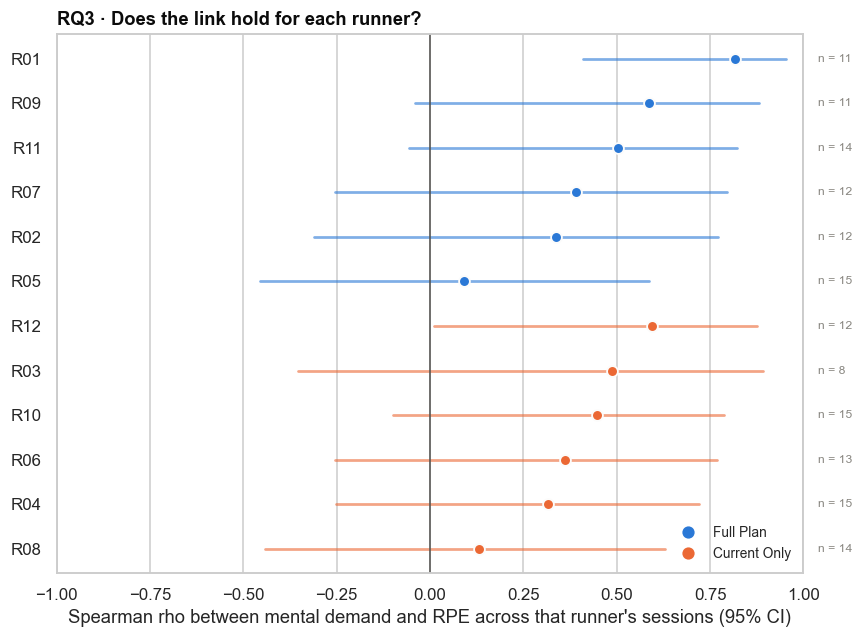

In [33]:
def plot_runner_forest(sessions):
    pr = per_runner_spearman(sessions[sessions["completed"]], "mental", "rpe")
    pr["condition"] = pd.Categorical(pr["condition"], CONDITIONS)
    pr = pr.sort_values(["condition", "rho"], ascending=[False, True]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8, 0.38 * len(pr) + 1.4))
    for i, r in pr.iterrows():
        ax.plot([r["lo"], r["hi"]], [i, i], color=COND_COLORS[r["condition"]], lw=1.8, alpha=0.6)
        ax.scatter(r["rho"], i, s=50, color=COND_COLORS[r["condition"]], edgecolor=SURFACE, lw=1.2, zorder=3)
        ax.text(1.04, i, f"n = {r['n']}", va="center", fontsize=8, color=MUTED)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(range(len(pr)), pr["participant_code"])
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Spearman rho between mental demand and RPE across that runner's sessions (95% CI)")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=7, color=COND_COLORS[c], label=c) for c in CONDITIONS],
              loc="lower right", fontsize=9)
    ax.set_title("RQ3 · Does the link hold for each runner?")
    fig.tight_layout()
    save_fig(fig, "fig08_rq3_per_runner")
    return fig, pr


_, per_runner = plot_runner_forest(sessions)

## 10. Content analysis of the diary answers (RQ1–RQ3)
### 10a. Codebook
| Diary question | RQ | What the codes capture |
|---|---|---|
| Did what you knew about upcoming sessions affect how hard you pushed? | RQ2 | Pacing decision (held back / pushed / no effect / unsure) and whether it came from knowing or not knowing what was next |
| What did you have to think about or keep track of? | RQ1 | Sources of cognitive load (structure, monitoring, logistics, finding the plan, looking ahead) |
| Did anything on your mind about the plan make the run easier or harder? | RQ3 | Direction of the effect and the mechanism (progress, rumination, uncertainty, present focus, surprise) |

In [34]:
codebook_table = pd.DataFrame([
    {"question": q, "type": "one per answer" if kind == "single" else "zero or more",
     "code": code, "definition": desc, "rule pattern": pat}
    for q, book in CODEBOOK.items() for kind in ("single", "multi") for code, (desc, pat) in book[kind].items()])
codebook_table.to_csv(OUT_DIR / "codebook.csv", index=False)
codebook_table[["question", "type", "code", "definition"]]

,question,type,code,definition
0,q_pacing,one per answer,HELD_BACK,Held back or saved energy
1,q_pacing,one per answer,PUSHED,Pushed harder than usual
2,q_pacing,one per answer,UNSURE,Unsure / went by feel
3,q_pacing,one per answer,NO_EFFECT,No effect on effort
4,q_pacing,zero or more,KNEW_UPCOMING,Mentions a specific upcoming session or the end of the plan that the runner ...
5,q_pacing,zero or more,UNCERTAIN_UPCOMING,Mentions not knowing what comes next
6,q_tracking,zero or more,SESSION_STRUCTURE,"Keeping track of the workout's structure (reps, recoveries, warm-up, blocks)"
7,q_tracking,zero or more,MONITORING,"Monitoring pace, time, or distance while running"
8,q_tracking,zero or more,LOGISTICS,"Practical preparation (route, water, food)"
9,q_tracking,zero or more,PLAN_ACCESS,"Finding, re-reading, or checking the session instructions"


### 10b. Coding: rule-based and LLM

In [35]:
rule_codes = code_responses_rules(text_responses)
llm_codes, llm_status = run_llm_coding(text_responses)
print(f"Rule-based coder: {len(rule_codes)} answers coded.")
print(f"LLM coder ({LLM_PROVIDER}): {len(llm_codes)} answers coded. Prompt files are in {LLM_DIR}/")
llm_status

Rule-based coder: 456 answers coded.
LLM coder (manual): 0 answers coded. Prompt files are in processed\llm_coding/


,batch,answers,coded,problems
0,q_pacing_batch01_prompt.txt,40,0,waiting for reply file
1,q_pacing_batch02_prompt.txt,40,0,waiting for reply file
2,q_pacing_batch03_prompt.txt,40,0,waiting for reply file
3,q_pacing_batch04_prompt.txt,32,0,waiting for reply file
4,q_tracking_batch01_prompt.txt,40,0,waiting for reply file
5,q_tracking_batch02_prompt.txt,40,0,waiting for reply file
6,q_tracking_batch03_prompt.txt,40,0,waiting for reply file
7,q_tracking_batch04_prompt.txt,32,0,waiting for reply file
8,q_plan_mind_batch01_prompt.txt,40,0,waiting for reply file
9,q_plan_mind_batch02_prompt.txt,40,0,waiting for reply file


**Coder agreement.** When LLM codes exist, each code is compared with the rule-based coder using Cohen's κ (≥ 0.61 substantial, ≥ 0.81 almost perfect; Landis & Koch, 1977). Codes with low agreement are reviewed by hand before use. A stratified **human validation sample** (25% of answers, blind to condition) is exported for two team members to code; once `human_validation_coded.csv` is filled in, the same table also reports human-vs-LLM agreement.

In [36]:
def agreement_table(a, b, name_a, name_b):
    m = a.merge(b, on=["response_id", "question"], suffixes=("_a", "_b"))
    rows = []
    for q, book in CODEBOOK.items():
        mq = m[m["question"] == q]
        cols = ([book["single_name"]] if book["single_name"] else []) + list(book["multi"])
        for c in cols:
            if len(mq) and f"{c}_a" in mq:
                rows.append({"comparison": f"{name_a} vs {name_b}", "question": q, "code": c, "answers": len(mq),
                             "% agree": 100 * np.mean(mq[f"{c}_a"].astype(str) == mq[f"{c}_b"].astype(str)),
                             "kappa": cohen_kappa(mq[f"{c}_a"], mq[f"{c}_b"])})
    return pd.DataFrame(rows)


sample = (text_responses[text_responses["question"].isin(CODED_QUESTIONS)]
          .groupby(["question", "condition"], observed=True).sample(frac=0.25, random_state=SEED))
human_file = OUT_DIR / "human_validation_sample.csv"
if not human_file.exists():
    sample[["response_id", "question", "response"]].sample(frac=1, random_state=SEED).to_csv(human_file, index=False)

agreement = []
if len(llm_codes):
    agreement.append(agreement_table(rule_codes, llm_codes, "rules", "LLM"))
coded_human = OUT_DIR / "human_validation_coded.csv"
if coded_human.exists():
    human = pd.read_csv(coded_human)
    if len(llm_codes):
        agreement.append(agreement_table(human, llm_codes, "human", "LLM"))
    agreement.append(agreement_table(human, rule_codes, "human", "rules"))
if agreement:
    display_agreement = pd.concat(agreement).round(2)
else:
    display_agreement = pd.DataFrame({"status": [f"No LLM or human codes yet. Paste the prompts in {LLM_DIR}/ into an LLM, "
                                                 "save each reply as the matching *_reply.txt file, and re-run."]})
display_agreement

,status
0,No LLM or human codes yet. Paste the prompts in processed\llm_coding/ into a...


In [37]:
use_llm = len(llm_codes) and llm_status["problems"].eq("").all()
codes = (llm_codes if use_llm else rule_codes).drop(columns="evidence", errors="ignore")
CODE_SOURCE = "LLM" if use_llm else "rule-based"
coded = text_responses.merge(codes, on=["response_id", "question"], how="inner")
coded.to_csv(OUT_DIR / "coded_responses.csv", index=False)
print(f"Analysis below uses {CODE_SOURCE} codes for {len(coded)} answers.")
uncoded = coded[(coded.get("pacing", pd.Series(dtype=str)) == "UNCODED") | (coded.get("valence", pd.Series(dtype=str)) == "UNCODED")]
print(f"Answers the coder could not place (review by hand): {len(uncoded)}")
uncoded[["response_id", "question", "response"]].head(10)

Analysis below uses rule-based codes for 456 answers.
Answers the coder could not place (review by hand): 0


,response_id,question,response


### 10c. Manipulation check from the diary text
If the manipulation worked, Full Plan runners should refer to upcoming sessions and the rest of the plan, while Current Only runners should mention not knowing what comes next and having to find each session's message. This complements the interview manipulation check.

In [38]:
def entry_level(coded):
    flags = {
        "used knowledge of upcoming sessions": ["KNEW_UPCOMING", "LOOK_AHEAD", "PROGRESS", "FORWARD_RUMINATION"],
        "mentioned not knowing what comes next": ["UNCERTAIN_UPCOMING", "UNCERTAINTY", "SURPRISE"],
        "had to find or re-read the session": ["PLAN_ACCESS"],
        "felt relief from focusing only on today": ["PRESENT_FOCUS"],
    }
    e = coded.copy()
    for name, cols in flags.items():
        e[name] = e[[c for c in cols if c in e]].fillna(False).astype(bool).any(axis=1)
    per_entry = e.groupby(["participant_code", "condition", "session_index"], observed=True)[list(flags)].any().reset_index()
    return per_entry, list(flags)


entries, check_cols = entry_level(coded)
manip = entries.groupby("condition", observed=True)[check_cols].mean().T * 100
manip["runners with ≥1 mention (FP / CO)"] = [
    f"{entries[entries.condition == 'Full Plan'].groupby('participant_code')[c].any().sum()} / "
    f"{entries[entries.condition == 'Current Only'].groupby('participant_code')[c].any().sum()}" for c in check_cols]
manip.round(1).rename(columns={c: f"% of entries · {c}" for c in CONDITIONS})

C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\890091829.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  e[name] = e[[c for c in cols if c in e]].fillna(False).astype(bool).any(axis=1)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\890091829.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  e[name] = e[[c for c in cols if c in e]].fillna(False).astype(bool).any(axis=1)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\890091829.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change 

condition,% of entries · Full Plan,% of entries · Current Only,runners with ≥1 mention (FP / CO)
used knowledge of upcoming sessions,90.7,6.5,6 / 4
mentioned not knowing what comes next,0.0,55.8,0 / 6
had to find or re-read the session,4.0,49.4,1 / 6
felt relief from focusing only on today,0.0,24.7,0 / 6


### 10d. Pacing decisions (RQ2): what runners said they did, by what came next
A diverging bar: **held back** extends left, **pushed** extends right, neutral answers sit in the middle. If anticipatory regulation is at work, Full Plan runners should hold back before harder sessions and push before easy runs and the final session; Current Only rows should look alike.

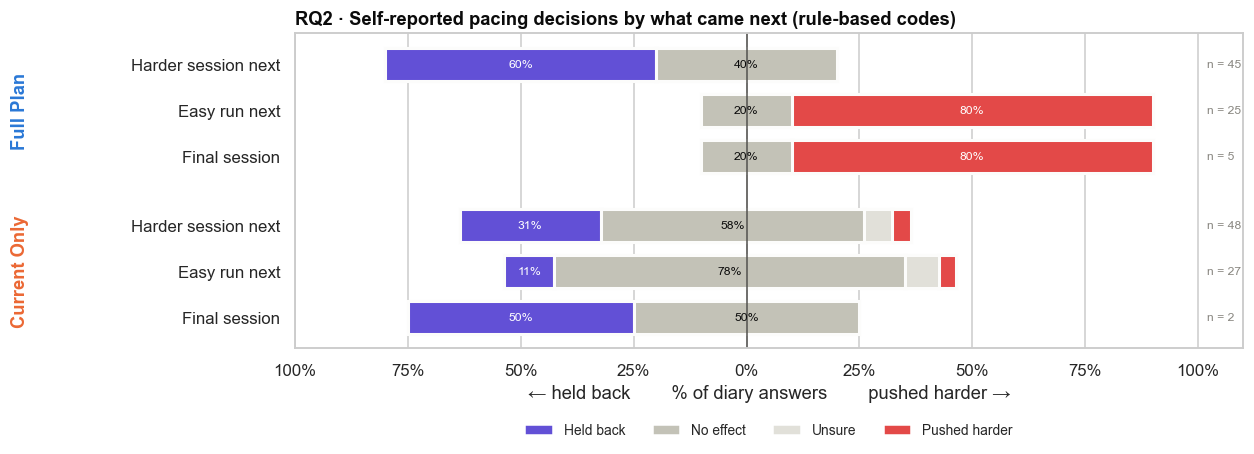

In [39]:
def plot_pacing_diverging(coded):
    d = coded[coded["question"] == "q_pacing"].copy()
    d["pacing"] = d["pacing"].replace({"UNCODED": "UNSURE"})
    cats = list(sessions["next_category"].cat.categories)
    rows = [(c, n) for c in CONDITIONS for n in cats]
    pct = (d.groupby(["condition", "next_category"], observed=True)["pacing"].value_counts(normalize=True)
           .unstack(fill_value=0).reindex(columns=["HELD_BACK", "NO_EFFECT", "UNSURE", "PUSHED"], fill_value=0) * 100)
    counts = d.groupby(["condition", "next_category"], observed=True).size()
    colors = {"HELD_BACK": "#6250d6", "NO_EFFECT": "#c3c2b7", "UNSURE": "#e1e0d9", "PUSHED": "#e34948"}
    labels = {"HELD_BACK": "Held back", "NO_EFFECT": "No effect", "UNSURE": "Unsure", "PUSHED": "Pushed harder"}
    fig, ax = plt.subplots(figsize=(11, 4.4))
    ylabels = []
    for i, (cond, nxt) in enumerate(rows):
        y = len(rows) - 1 - i + (0.5 if cond == "Full Plan" else 0)
        if (cond, nxt) not in pct.index:
            continue
        p = pct.loc[(cond, nxt)]
        neutral = p["NO_EFFECT"] + p["UNSURE"]
        segs = [("HELD_BACK", -neutral / 2 - p["HELD_BACK"], p["HELD_BACK"]),
                ("NO_EFFECT", -neutral / 2, p["NO_EFFECT"]),
                ("UNSURE", -neutral / 2 + p["NO_EFFECT"], p["UNSURE"]),
                ("PUSHED", neutral / 2, p["PUSHED"])]
        for code, left, width in segs:
            if width <= 0:
                continue
            ax.barh(y, width, left=left, height=0.72, color=colors[code], edgecolor=SURFACE, linewidth=2)
            if width >= 9:
                ax.text(left + width / 2, y, f"{width:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if code in ("HELD_BACK", "PUSHED") else INK)
        ax.text(102, y, f"n = {counts.loc[(cond, nxt)]}", va="center", fontsize=8, color=MUTED)
        ylabels.append((y, nxt.capitalize(), cond))
    ax.set_yticks([y for y, *_ in ylabels], [l for _, l, _ in ylabels])
    for cond in CONDITIONS:
        ys = [y for y, _, c in ylabels if c == cond]
        ax.annotate(cond, (-0.29, np.mean(ys)), xycoords=("axes fraction", "data"), rotation=90, ha="center",
                    va="center", color=COND_COLORS[cond], fontweight="bold", annotation_clip=False)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_xlim(-100, 110)
    ax.set_xticks(range(-100, 101, 25), [f"{abs(v)}%" for v in range(-100, 101, 25)])
    ax.set_xlabel("← held back        % of diary answers        pushed harder →")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(facecolor=colors[c], label=labels[c]) for c in colors],
              loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=9)
    ax.set_title(f"RQ2 · Self-reported pacing decisions by what came next ({CODE_SOURCE} codes)")
    fig.tight_layout()
    fig.subplots_adjust(left=0.2)
    save_fig(fig, "fig09_pacing_diverging")
    return fig


plot_pacing_diverging(coded);

### 10e. How themes change over the plan
Share of answers mentioning each theme, by condition and week. Look for themes that belong to one condition (e.g., *Uncertainty* in Current Only) and themes that grow toward the end of the plan (e.g., *Progress* in Full Plan).

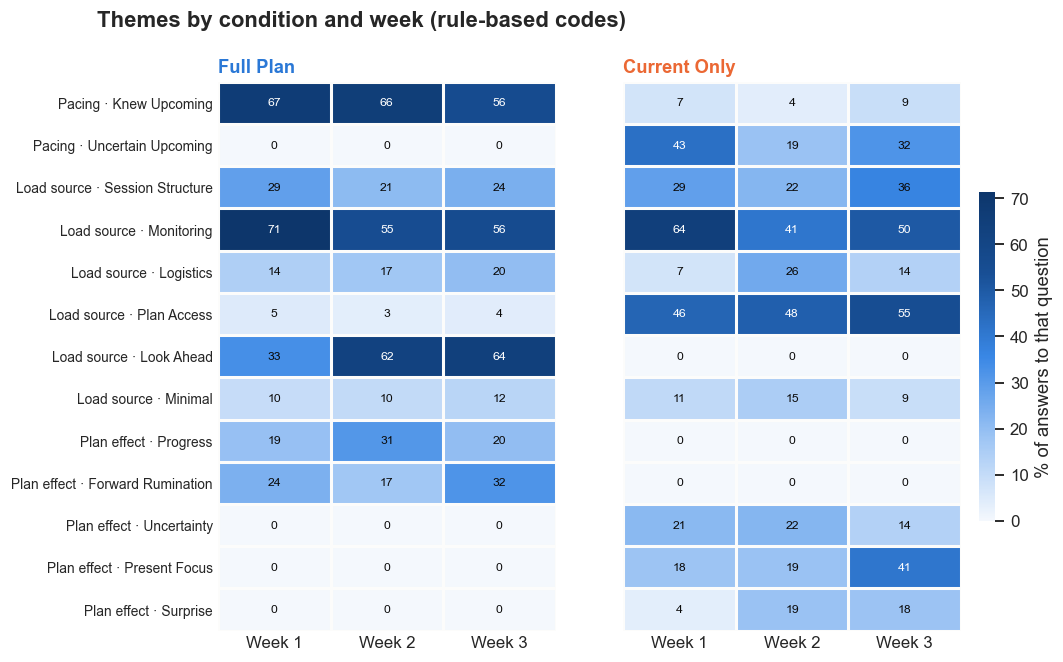

In [40]:
def plot_theme_heatmap(coded):
    themes = [(q, c) for q in CODED_QUESTIONS for c in CODEBOOK[q]["multi"]]
    qlabel = {"q_pacing": "Pacing", "q_tracking": "Load source", "q_plan_mind": "Plan effect"}
    mats = {}
    for cond in CONDITIONS:
        m = np.full((len(themes), N_WEEKS), np.nan)
        for i, (q, c) in enumerate(themes):
            sub = coded[(coded["condition"] == cond) & (coded["question"] == q)]
            m[i] = sub.groupby("week")[c].mean().reindex(range(1, N_WEEKS + 1)).to_numpy(float) * 100
        mats[cond] = m
    vmax = max(np.nanmax(m) for m in mats.values())
    cmap = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#9ec5f4", "#3987e5", "#184f95", "#0d366b"])
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 0.36 * len(themes) + 1.8), sharey=True)
    for ax, cond in zip(axes, CONDITIONS):
        im = ax.imshow(mats[cond], cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
        for i in range(len(themes)):
            for j in range(N_WEEKS):
                v = mats[cond][i, j]
                if np.isfinite(v):
                    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                            color="white" if v > vmax * 0.55 else INK)
        ax.set_xticks(range(N_WEEKS), [f"Week {w}" for w in range(1, N_WEEKS + 1)])
        ax.set_title(cond, color=COND_COLORS[cond])
        ax.grid(False)
        ax.set_xticks(np.arange(-.5, N_WEEKS, 1), minor=True)
        ax.set_yticks(np.arange(-.5, len(themes), 1), minor=True)
        ax.grid(which="minor", color=SURFACE, lw=2)
        ax.tick_params(which="both", length=0)
        for sp in ax.spines.values():
            sp.set_visible(False)
    axes[0].set_yticks(range(len(themes)), [f"{qlabel[q]} · {c.replace('_', ' ').title()}" for q, c in themes], fontsize=9)
    cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
    cb.set_label("% of answers to that question")
    cb.outline.set_visible(False)
    fig.suptitle(f"Themes by condition and week ({CODE_SOURCE} codes)", x=0.02, ha="left", fontweight="bold")
    save_fig(fig, "fig10_theme_heatmap")
    return fig


plot_theme_heatmap(coded);

### 10f. Example quotes per theme
For the write-up, a few answers per theme and condition (labelled by participant code and session only). Check every quote for identifying details before using it.

In [41]:
def exemplar_quotes(coded, per_cell=2):
    rows = []
    for q in CODED_QUESTIONS:
        for c in CODEBOOK[q]["multi"]:
            for cond in CONDITIONS:
                sub = coded[(coded["question"] == q) & (coded["condition"] == cond) & coded[c].fillna(False).astype(bool)
                            & coded["substantive"]]
                sub = sub.drop_duplicates("participant_code").sample(frac=1, random_state=SEED).head(per_cell)
                for _, r in sub.iterrows():
                    rows.append({"theme": c, "condition": cond, "who": f"{r['participant_code']} · W{r['week']} S{r['session']}",
                                 "quote": r["response"]})
    return pd.DataFrame(rows)


quotes = exemplar_quotes(coded)
quotes.to_csv(OUT_DIR / "exemplar_quotes.csv", index=False)
quotes.head(24)

C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\3883983293.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sub = coded[(coded["question"] == q) & (coded["condition"] == cond) & coded[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\3883983293.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sub = coded[(coded["question"] == q) & (coded["condition"] == cond) & coded[c].fillna(False).astype(bool)
C:\Users\Adrian\AppData\Local\Temp\ipykernel_22648\3883983293.py:6: FutureWarning: Downcasting object dtype arrays on .f

,theme,condition,who,quote
0,KNEW_UPCOMING,Full Plan,R02 · W1 S2,"Yes, the next one is only an easy run so I felt fine pushing today."
1,KNEW_UPCOMING,Full Plan,R05 · W1 S2,"A bit. I could recover on the easy run next, so I worked harder."
2,KNEW_UPCOMING,Current Only,R08 · W1 S2,"slightly, I didn't want to wreck my legs in case the next one is hard"
3,KNEW_UPCOMING,Current Only,R12 · W3 S4,"Slightly, I didn't want to wreck my legs in case the next one is hard."
4,UNCERTAIN_UPCOMING,Current Only,R04 · W1 S1,A bit. Not knowing the next session made me hold back on the last part.
5,UNCERTAIN_UPCOMING,Current Only,R06 · W1 S2,Hard to say. I don't know what's next so I went by feel.
6,SESSION_STRUCTURE,Full Plan,R02 · W1 S2,Had to reread the session to get the intervals right.
7,SESSION_STRUCTURE,Full Plan,R05 · W1 S2,Fast pace targets and counting reps.
8,SESSION_STRUCTURE,Current Only,R04 · W1 S2,"Number of reps, rest times, and my watch timer."
9,SESSION_STRUCTURE,Current Only,R06 · W1 S2,Had to reread the session to get the intervals right.


## 11. Sensitivity analysis
Do the condition differences depend on cleaning decisions? Each row re-computes the runner-level difference after removing one category of questionable data. A finding that changes direction across rows should not be reported without that caveat.

In [42]:
SCENARIOS = {
    "All completed sessions": None,
    "Excluding late entries (> 2 h)": ~sessions["flag_late"],
    "Sessions run as prescribed only": sessions["status"].eq("prescribed"),
    "Excluding any quality flag": ~sessions["any_quality_flag"],
    "Excluding the withdrawn runner": ~sessions["participant_code"].isin(
        sessions.loc[sessions["status"] == "withdrawn", "participant_code"].unique()),
}
sens = []
for name, mask in SCENARIOS.items():
    pm = participant_means(sessions, list(OUTCOMES), mask)
    for col, label in OUTCOMES.items():
        a = pm.loc[pm.condition == "Full Plan", col].dropna()
        b = pm.loc[pm.condition == "Current Only", col].dropna()
        sens.append({"scenario": name, "outcome": label, "sessions used": int(sessions["completed"].sum() if mask is None
                     else (sessions["completed"] & mask).sum()), "FP mean": a.mean(), "CO mean": b.mean(),
                     "difference": a.mean() - b.mean(), "Hedges g": hedges_g(a, b)})
sensitivity = pd.DataFrame(sens)
sensitivity.pivot(index="scenario", columns="outcome", values="difference").loc[list(SCENARIOS)].round(2)

outcome,Borg RPE (6-20),Mental demand (0-100),Raw TLX (0-100)
scenario,,,
All completed sessions,1.56,20.76,9.11
Excluding late entries (> 2 h),1.48,20.11,8.80
Sessions run as prescribed only,1.60,20.62,8.73
Excluding any quality flag,1.48,20.11,8.80
Excluding the withdrawn runner,1.38,21.92,8.55


### Stability of Borg RPE using Leave-One-Out (LOO)

Leave-One-Out process is used to help determine whether if a particular runner has an unusually large influence on the mean RPE, separated by condition.

=== LEAVE-ONE-OUT SENSITIVITY SUMMARY ===
      condition  Baseline_LOO_Mean   Min_Mean   Max_Mean  Max_Range  Std_of_Means
0  Current Only          12.571048  12.384615  12.758065   0.373449      0.097295
1     Full Plan           14.11904  13.733333  14.396825   0.663492      0.165115


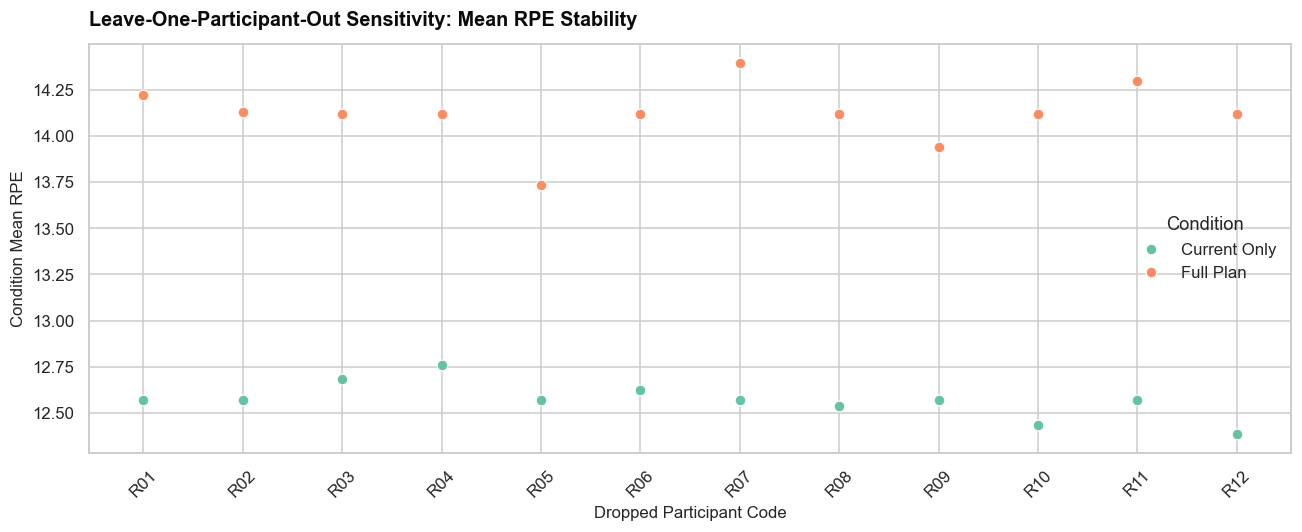

In [43]:
# 1. Identify unique participants
participants = rpe_df["participant_code"].dropna().unique()

loo_records = []

# 2. Iterate and drop one participant at a time
for p in participants:
  subset = rpe_df[rpe_df["participant_code"] != p]

  # Calculate summary stats for the remaining sample
  stats = (
      subset.groupby("condition")["rpe"]
      .agg(
          Mean="mean",
          Std="std",
          Median="median",
          IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
          Count="count",
      )
      .reset_index()
  )

  stats["dropped_participant"] = str(p)
  loo_records.append(stats)

# Combine into a single DataFrame
loo_df = pd.concat(loo_records, ignore_index=True)

# 3. Get overall Stability Summary Across LOO Iterations
stability_summary = (
    loo_df.groupby("condition")["Mean"]
    .agg(
        Baseline_LOO_Mean="mean",
        Min_Mean="min",
        Max_Mean="max",
        Max_Range=lambda x: x.max() - x.min(),  # Total fluctuation span
        Std_of_Means="std",  # Lower = more stable
    )
    .reset_index()
)

print("=== LEAVE-ONE-OUT SENSITIVITY SUMMARY ===")
print(stability_summary)

# 4. Plot LOO Stability Trajectory
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

# Plot mean RPE for each condition as participants are dropped one by one
ax = sns.lineplot(
    data=loo_df,
    x="dropped_participant",
    y="Mean",
    hue="condition",
    marker="o",
    palette="Set2",
    linewidth=0,
    markersize=7,
)

plt.title(
    "Leave-One-Participant-Out Sensitivity: Mean RPE Stability",
    fontsize=13,
    pad=12,
)
plt.xlabel("Dropped Participant Code", fontsize=11)
plt.ylabel("Condition Mean RPE", fontsize=11)
plt.xticks(rotation=45)
plt.legend(title="Condition", loc="best")

plt.tight_layout()
plt.show()

In [44]:
# Pivot to compute condition difference (e.g., Condition A - Condition B) per iteration
loo_pivot = loo_df.pivot(
    index="dropped_participant", columns="condition", values="Mean"
)

# Use current only as baseline
if len(loo_pivot.columns) >= 2:
  cond_a, cond_b = loo_pivot.columns[1], loo_pivot.columns[0]
  loo_pivot["Mean_Difference"] = loo_pivot[cond_a] - loo_pivot[cond_b]

  print(f"\n=== MEAN DIFFERENCE ({cond_a} vs {cond_b}) STABILITY ===")
  print(loo_pivot[["Mean_Difference"]].describe())


=== MEAN DIFFERENCE (Full Plan vs Current Only) STABILITY ===
condition  Mean_Difference
count                 12.0
mean              1.547991
std               0.191651
min               1.161905
25%               1.420648
50%               1.567937
75%                 1.6943
max               1.825397


### Sensitivity Analysis using different exclusion scenarios

Filtering rules are applied to the dataset:
- **All completed sessions**: Includes all data without filtering.
- **Excluding late entries (> 2 h)**: Excludes sessions flagged as late `(~sessions["flag_late"])`.
- **Sessions run as prescribed only**: Keeps only sessions where execution matched protocol `(status == "prescribed")`.
- **Excluding any quality flag**: Filters out any session flagged for quality issues `(~sessions["any_quality_flag"]`).
- **Excluding the withdrawn runner**: Excludes all sessions belonging to participants marked as `"withdrawn"`.

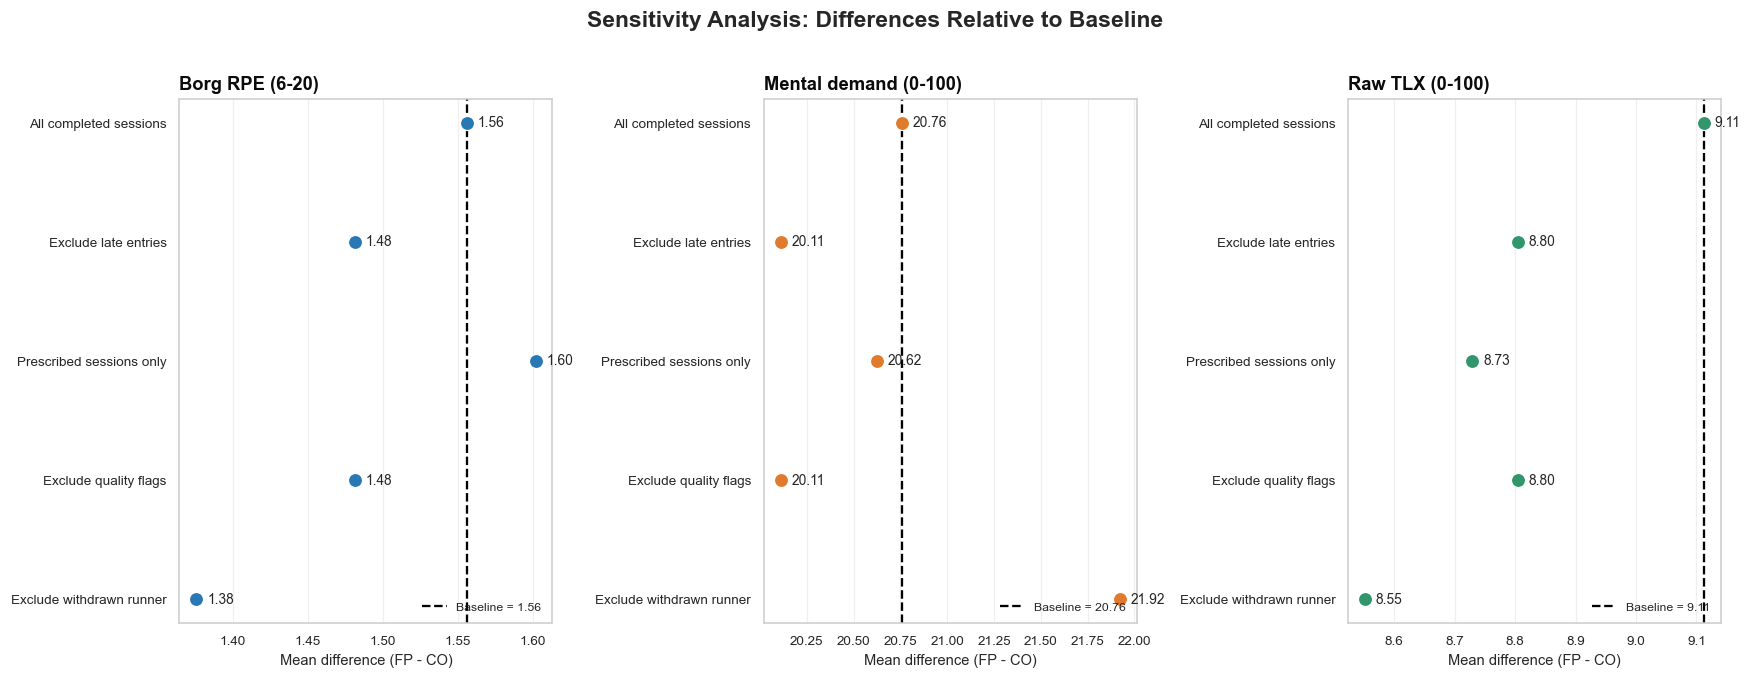

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Scenario order
scenario_order = list(SCENARIOS.keys())

outcome_order = [
    "Borg RPE (6-20)",
    "Mental demand (0-100)",
    "Raw TLX (0-100)"
]

short_labels = [
    "All completed sessions",
    "Exclude late entries",
    "Prescribed sessions only",
    "Exclude quality flags",
    "Exclude withdrawn runner"
]

colors = ["#2878B5", "#E07A2D", "#31966B"]

sns.set_theme(style="whitegrid", context="paper")

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6)
)

for ax, outcome, color in zip(
    axes, outcome_order, colors
):

    subset = (
        sensitivity[
            sensitivity["outcome"] == outcome
        ]
        .set_index("scenario")
        .loc[scenario_order]
    )

    differences = subset["difference"].values
    baseline = differences[0]

    y = np.arange(len(scenario_order))

    # Plot baseline reference line
    ax.axvline(
        baseline,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Baseline = {baseline:.2f}"
    )

    # Plot scenario estimates
    ax.scatter(
        differences,
        y,
        color=color,
        s=85,
        zorder=3,
        edgecolor="white",
        linewidth=0.8
    )

    # Numerical labels
    for x, ypos in zip(differences, y):
        ax.annotate(
            f"{x:.2f}",
            (x, ypos),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

    ax.set_yticks(y)
    ax.set_yticklabels(short_labels)

    ax.invert_yaxis()

    ax.set_title(
        outcome,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Mean difference (FP - CO)")

    ax.grid(
        axis="x",
        alpha=0.3
    )

    ax.grid(
        axis="y",
        visible=False
    )

    ax.legend(
        frameon=False,
        fontsize=8,
        loc="lower right"
    )

fig.suptitle(
    "Sensitivity Analysis: Differences Relative to Baseline",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.show()

### Quantified stability metrics

- `baseline`: The mean difference `(FP - CO)` from the unfiltered dataset
- `max_absolute_deviation`: The maximum shift observed between the baseline and filtered scenario.
- `max_percentage_deviation`: The maximum relative change from baseline expressed as a percentage
- `directional_consistency`: The percentage of scenarios where the mean difference maintains the same algebraic sign as the baseline.

In [46]:
stability_results = []

for outcome in sensitivity["outcome"].unique():

    sub = sensitivity[
        sensitivity["outcome"] == outcome
    ].copy()

    baseline = sub.loc[
        sub["scenario"] == "All completed sessions",
        "difference"
    ].iloc[0]

    # Exclude baseline when assessing alternative scenarios
    exclusions = sub[
        sub["scenario"] != "All completed sessions"
    ].copy()

    exclusions["change"] = (
        exclusions["difference"] - baseline
    )

    exclusions["percent_change"] = (
        exclusions["change"] / abs(baseline)
    ) * 100

    stability_results.append({
        "outcome": outcome,
        "baseline": baseline,
        "max_absolute_deviation":
            exclusions["change"].abs().max(),
        "max_percentage_deviation":
            exclusions["percent_change"].abs().max(),
        "directional_consistency":
            (
                np.sign(sub["difference"]) == np.sign(baseline)
            ).mean() * 100
    })

stability = pd.DataFrame(stability_results)

display(stability.round(2))


,outcome,baseline,max_absolute_deviation,max_percentage_deviation,directional_consistency
0,Mental demand (0-100),20.76,1.17,5.62,100.0
1,Borg RPE (6-20),1.56,0.18,11.60,100.0
2,Raw TLX (0-100),9.11,0.56,6.16,100.0


## 12. Summary and export
The cell below prints the headline numbers in one place. **On synthetic data these only confirm that the pipeline recovers the planted effects** (mental demand +15 and RPE +1 for Full Plan, on average; any single sample lands near these values, not on them). The generator writes pacing comments that follow anticipatory regulation, but it does not make the *ratings* follow those comments, so Figure 6 is expected to look flat on this data.

In [47]:
fmt = lambda r: f"{r['diff']:+.2f} [{r['diff_lo']:+.2f}, {r['diff_hi']:+.2f}]"
rq3_all = rmcorr(done, "mental", "rpe")
print("DATA" + (" (SYNTHETIC: not results)" if IS_SYNTHETIC else ""))
print(f"  {participants.shape[0]} runners, {int(sessions['completed'].sum())} completed sessions, "
      f"{int(sessions['status'].eq('skipped').sum())} skipped, {int(sessions['status'].eq('missing').sum())} missing, "
      f"{sessions.loc[sessions.status == 'withdrawn', 'participant_code'].nunique()} withdrawal(s)")
print(f"  Tests: {(test_results.result == 'PASS').sum()} passed, {(test_results.result == 'FAIL').sum()} failed")
print("RQ1  Mental demand, Full Plan − Current Only:", fmt(est_results["mental"]), "points (0-100)")
print("     Raw TLX, Full Plan − Current Only:      ", fmt(est_results["tlx_raw"]), "points (0-100)")
print("RQ2  RPE, Full Plan − Current Only:          ", fmt(est_results["rpe"]), "points (6-20)")
print(f"RQ3  Within-runner r_rm (mental, RPE) = {rq3_all['r']:.2f}; between-runner rho = "
      f"{stats.spearmanr(pm_all['mental'], pm_all['rpe']).statistic:.2f}")
print(f"Content analysis uses {CODE_SOURCE} codes; manipulation check (entries using upcoming-session knowledge): "
      + ", ".join(f"{c} {manip.loc['used knowledge of upcoming sessions', c]:.0f}%" for c in CONDITIONS))
print("\nFiles written:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and "llm_coding" not in p.parts:
        print("  ", p)

AttributeError: 'DataFrame' object has no attribute 't'